# Active sampling evaluation

First shows how much the build matters per hardware (needs only the measurements). Then ranks every historical → local pair by **AUC** (area under the best-build-so-far curve) and looks at the top 10: their curves, the full pair grid, the local models, and tuning time vs. performance gain.

- **Input:** the CSVs of `python -m ml.main evaluate`: simulated replays (`--mode simulate`) or live sessions (`--mode live`, one `active-*` folder each). Set `RESULTS` below.
- **llama.cpp ↔ GROMACS:** change `APP`; everything else follows from it.
- **Default build:** set `DEFAULT_BUILD` once it is fixed; the baselines and the gain then use it automatically.

### What to run with new measurements

1. Right after measuring: run the cells up to and including section 1 (spread of the builds per hardware); no evaluation needed.
2. Remove the old runs: `rm -r evaluation/results/llama.cpp/test-subset` (a small test run; every run below `evaluation/results/<app>/` is read).
3. Simulate all pairs on the measured builds, from the repository root. Use a fresh `--output` folder; finished sessions are written as they complete, so an interrupted run is still readable (it cannot be resumed). The full llama.cpp grid is about 100 CPU hours; each job needs about 1.5 GB RAM. Add `--model …` / `--pretrained …` to run only some pairs.
   ```bash
   .venv/bin/python -m ml.main evaluate --app llama.cpp --data llama/results --prompt 512 --generate 128 \
     --steps 25 --initial 2 --seeds 3 --jobs 3 --output evaluation/results/llama.cpp/sim-3seeds
   .venv/bin/python -m ml.main evaluate --app gromacs --data gromacs/results \
     --steps 25 --initial 2 --seeds 3 --jobs 3 --output evaluation/results/gromacs/sim-3seeds
   ```
4. Open this notebook, set `APP`, *Run All*.
5. Later, live sessions (`ml.main evaluate --mode live`, see the README): copy their `active-*` folders to `evaluation/results/<app>/live/`; set `MODE = "live"` to look at them alone.

In [24]:
from pathlib import Path
import contextlib
import io
import json
import sys
import warnings
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.special import gammaln

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml" / "load.py").is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from ml.load import CFG, app_options, load_table, parse_run, read_runs, strip

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.precision", 2)

In [25]:
APP = "llama.cpp"   # "llama.cpp" or "gromacs": the one line to change

RESULTS = {   # evaluation CSVs: run folder(s) or ZIP(s); folders are searched recursively (also for live active-* sessions)
    "llama.cpp": [REPO / "evaluation" / "results" / "llama.cpp"],
    "gromacs": [REPO / "evaluation" / "results" / "gromacs"],
}[APP]
DATA = REPO / {"llama.cpp": "llama", "gromacs": "gromacs"}[APP] / "results"   # measured builds (the pools)
DEFAULT_BUILD = {   # the default build once it is fixed, as {option: value}, e.g. {"-O": "-O3", "GGML_NATIVE": "ON"}
    "llama.cpp": None,
    "gromacs": None,
}[APP]
MODE = None                  # None: every session found; "simulate" or "live": only that kind
BUDGET = 25                  # builds per session; AUC covers the steps after the start builds up to here
TOP_N = 10
ONE_PER_HISTORICAL = False   # True: at most one pair per historical model in the top list

UNIT = {"llama.cpp": "tokens/s", "gromacs": "ns/day"}[APP]
SHORT = {   # display names; other platforms keep their full name
    "-": "M4 (Davide CPU)",   # M4 runs do not record the CPU name
    "AMD Ryzen 7 5800X 8-Core Processor": "5800X (Davide CPU)",
    "AMD Ryzen 7 5800X 8-Core Processor + Vulkan device": "5800X+Vulkan (Davide GPU)",
    "AMD Ryzen 7 8845HS w/ Radeon 780M Graphics": "8845HS (Sonja CPU)",
    "AMD Ryzen 9 3900X 12-Core Processor": "3900X (Jakob CPU)",
    "AMD Ryzen Threadripper 1950X 16-Core Processor": "TR1950X (Jakob CPU)",
    "AMD Ryzen Threadripper 1950X 16-Core Processor + CUDA device": "TR1950X+CUDA (Jakob GPU)",
    "Apple M1 Max": "M1 Max (Theo CPU)",
    "Cortex-X925 + CUDA device": "GB10 (Theo GPU)",
    "Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz": "i5-1038NG7 (Magda CPU)",
    "Intel(R) Xeon(R) CPU E5-2680 v4 @ 2.40GHz + CUDA device": "Xeon E5+5060Ti (Theo GPU)",
}

In [26]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, SURFACE, NEUTRAL = "#0b0b0b", "#52514e", "#898781", "#e6e5e0", "#ffffff", "#c3c2b7"
ACCENT, OTHER, BELOW = SERIES[1], "#a9a8a0", "#d65e12"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": NEUTRAL, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 150, "font.size": 12,
                     "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Arimo", "Liberation Sans", "DejaVu Sans"],
                     "axes.titlesize": 13, "axes.labelsize": 12, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5,
                     "legend.fontsize": 10.5})
TITLE_STYLE = dict(loc="left", fontsize=15, fontweight="bold", pad=10)


def label_bottom(axes, used, text):
    # x label on the lowest used panel of each column; hide unused panels
    rows_, cols_ = axes.shape
    for i, ax in enumerate(axes.flat):
        ax.set_visible(i < used)
    for col in range(cols_):
        last = max((r for r in range(rows_) if r * cols_ + col < used), default=None)
        if last is not None:
            axes[last, col].set_xlabel(text)


def style_axis(ax, grid="x"):
    ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

In [27]:
COLD = "(cold start)"
RANDOM_PAIR = (COLD, "random")
PAIR = ["historical", "local"]
KEY = ["run", "platform", "pretrained", "model", "seed"]
TWINS = {"hardware": "ridge", "no-hardware": "ridge", "hardware-interactions": "ridge-pairs",
         "no-hardware-interactions": "ridge-pairs", "hardware-three-way": "ridge-pairs"}


def local_family(model):
    name = model.removeprefix("corrected-")
    return TWINS.get(name, name.removeprefix("no-hardware-"))


def short(platform):
    return SHORT.get(platform, platform)


def label(pair):
    return f"{pair[0]} → {pair[1]}"


@contextlib.contextmanager
def quiet():
    with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
        warnings.simplefilter("ignore")
        yield


def evaluation_tables(paths, name):
    # Every evaluation.<name>.csv below the folders and inside the ZIPs, tagged with the run it came from.
    frames = []
    for path in map(Path, paths):
        files = sorted(path.rglob(f"evaluation.{name}.csv")) if path.is_dir() else []
        frames += [pd.read_csv(f, keep_default_na=False, na_values=[""]).assign(run=str(f.parent.relative_to(path)))
                   for f in files]
        for archive_path in [path] if path.suffix == ".zip" else sorted(path.rglob("*.zip")) if path.is_dir() else []:
            with zipfile.ZipFile(archive_path) as archive:
                for member in sorted(m for m in archive.namelist() if m.endswith(f"evaluation.{name}.csv")):
                    with archive.open(member) as handle:
                        frames.append(pd.read_csv(handle, keep_default_na=False, na_values=[""])
                                      .assign(run=f"{archive_path.name}:{Path(member).parent}"))
    if not frames:
        raise FileNotFoundError(f"no evaluation.{name}.csv in {[str(p) for p in paths]}")
    return pd.concat(frames, ignore_index=True)


def raw_runs(path):
    # One row per measured run: benchmark noise (relative std), build + benchmark seconds, start time.
    rows = []
    for files in read_runs([path]):
        try:
            row = parse_run(files, APP)
            build, bench = json.loads(files["build.json"]), json.loads(files["benchmark.json"])
        except (json.JSONDecodeError, KeyError, TypeError):
            continue
        if row is None:
            continue
        if APP == "llama.cpp":
            total = sum(float(t["avg_ns"]) for t in bench)
            noise = np.sqrt(sum(float(t["stddev_ns"]) ** 2 for t in bench)) / total
            start = min(t["test_time"] for t in bench)
        else:
            noise, start = bench["std"] / bench["mean"], build.get("run_timestamp_utc")
        seconds = (build.get("build_time_seconds") or np.nan) + (build.get("benchmark_wall_seconds") or np.nan)
        rows.append(dict(platform=short(row["platform"]), run_id=row["run_id"], performance=row["performance"],
                         noise=noise, seconds=seconds, start=pd.to_datetime(start, utc=True, errors="coerce")))
    return pd.DataFrame(rows)


def expected_best(values, ns):
    # Exact expected best of n uniform random picks without replacement (what random search finds on average).
    v, out = np.sort(np.asarray(values, float)), []
    N, k = len(v), np.arange(1, len(v) + 1)
    log_choose = lambda a, b: gammaln(a + 1) - gammaln(b + 1) - gammaln(a - b + 1)
    for n in ns:
        n, weight = min(n, N), np.zeros(N)
        ok = k >= n
        weight[ok] = np.exp(log_choose(k[ok] - 1, n - 1) - log_choose(N, n))
        out.append(weight @ v)
    return np.array(out)


def build_keys(rows):
    # The JSON the evaluation writes for a build (attempted_build), per pool row.
    cols = [c for c in app_options(rows).columns if c.startswith(CFG)]
    return [json.dumps(dict(zip(map(strip, cols), values)), sort_keys=True, default=str)
            for values in rows[cols].itertuples(index=False, name=None)]

## 1. Data Analysis: how is the data distributed? do the flags matter?

Needs only the measurements (`DATA`), so it also runs before any evaluation exists. Every measured build (repeated measurements averaged, `ml.load`) as % of that hardware's best build. **Noise** is the relative standard deviation between repeated measurements of the same build (where ≥ 5 builds were repeated), otherwise within one benchmark run (a lower bound). The flags make a **noticeable difference** where the median build is further from the best than 2 × noise.

In [28]:
with quiet():
    pool = load_table([DATA], app=APP, skip_invalid_json=True)
    raw = raw_runs(DATA)
pool["platform"] = pool.platform.map(short)
pool["pct"] = 100 * pool.relative


def default_performance():
    if not DEFAULT_BUILD:
        return pd.Series(dtype=float)
    missing = [o for o in DEFAULT_BUILD if CFG + o not in pool]
    if missing:
        raise KeyError(f"DEFAULT_BUILD options not in the data: {missing}")
    match = np.logical_and.reduce([pool[CFG + o].astype(str) == str(v) for o, v in DEFAULT_BUILD.items()])
    counts = pool[match].groupby("platform").size()
    if (counts > 1).any():
        print("DEFAULT_BUILD matches several builds on", list(counts[counts > 1].index), "→ their mean is used")
    return pool[match].groupby("platform").performance.mean()


default_perf = default_performance()   # empty until DEFAULT_BUILD is set

In [29]:
# Table 0: how many on/off flags are on per measured build, per hardware (number of builds per count)
# On/off flags: options with only ON/OFF or -fX/-fno-X values; counted per hardware only where they vary there
# (fixed backends such as GGML_CUDA are left out). Multi-valued options (-O, -march, …) are not counted.
def flag_state(values):
    on = values.isin(["ON"]) | (values.str.startswith("-f") & ~values.str.startswith("-fno-"))
    off = values.isin(["OFF", "default"]) | values.str.startswith("-fno-")
    return on.where(on | off)   # NaN: not an on/off value


flag_rows = []
for platform, builds in pool.groupby("platform"):
    states = pd.DataFrame({c.removeprefix(CFG): flag_state(builds[c].astype(str)) for c in builds if c.startswith(CFG)})
    flags = [c for c in states if states[c].notna().all() and states[c].nunique() == 2]
    on = states[flags].sum(axis=1).astype(int)
    flag_rows.append(on.value_counts().rename(platform).to_frame().T.assign(**{"on/off flags": len(flags),
                                                                                "mean on": on.mean()}))
flags_on = pd.concat(flag_rows).fillna(0)
counts = sorted(c for c in flags_on if isinstance(c, (int, np.integer)))
flags_on = flags_on[["on/off flags", "mean on", *counts]].astype({c: int for c in ["on/off flags", *counts]})
flags_on.columns.name = "flags on →"
display(flags_on.style.format(precision=1).format(lambda v: v or "·", subset=counts))


flags on →,on/off flags,mean on,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21
3900X (Jakob CPU),18,7.5,4,17,·,·,4,3,5,11,20,20,11,17,6,2,1,·,·,·,·,·,·
5800X (Davide CPU),17,8.6,·,·,·,·,9,10,39,57,60,69,66,33,22,6,·,·,·,·,·,·,·
5800X+Vulkan (Davide GPU),18,8.3,9,30,45,24,34,36,53,74,97,113,111,71,54,34,17,15,12,7,6,·,·
8845HS (Sonja CPU),22,6.4,3,5,3,2,3,2,2,·,·,1,3,·,·,·,·,1,1,2,1,1,·
GB10 (Theo GPU),20,6.4,·,2,17,35,31,29,30,19,21,12,9,7,4,8,5,7,3,·,·,·,·
M1 Max (Theo CPU),13,5.2,11,24,43,23,26,17,27,16,12,12,19,4,9,9,·,·,·,·,·,·,·
M4 (Davide CPU),12,4.8,1,11,11,8,7,5,3,6,4,3,4,3,2,·,·,·,·,·,·,·,·
TR1950X (Jakob CPU),18,6.8,3,11,4,5,3,4,4,2,4,4,2,1,3,1,4,·,6,·,1,·,·
Xeon E5+5060Ti (Theo GPU),26,5.6,1,2,14,29,17,6,7,1,8,2,3,5,1,1,2,1,2,1,1,·,1
i5-1038NG7 (Magda CPU),21,9.3,1,1,·,·,2,2,5,2,4,12,7,8,3,2,3,1,1,1,·,·,·


In [30]:
# Noise and build time per pool row (from the individual runs)
ids = (pool[["platform", "run_id"]].assign(run_id=pool.run_id.str.split(",")).explode("run_id")
       .reset_index().merge(raw, on=["platform", "run_id"], how="left"))
pool["seconds"] = ids.groupby("index").seconds.median()
pool["noise"] = ids.groupby("index").noise.median()
repeats = ids.groupby("index").performance.agg(lambda s: s.std() / s.mean() if s.count() > 1 else np.nan)
pool["repeat_cv"] = repeats

by_platform = pool.groupby("platform")
repeat_count = by_platform.repeat_cv.count()
noise = (100 * by_platform.repeat_cv.median()).where(repeat_count >= 5, 100 * by_platform.noise.median())
spread = pd.DataFrame({
    "builds": by_platform.size(),
    "median (%)": by_platform.pct.median(),
    "p10 (%)": by_platform.pct.quantile(0.1),
    "within 2 % of best": by_platform.pct.agg(lambda s: (s >= 98).mean()),
    "best vs median (+%)": 100 * (by_platform.performance.max() / by_platform.performance.median() - 1),
    "noise (%)": noise, "noise from": np.where(repeat_count >= 5, "repeats", "within run (lower bound)"),
    "default build (%)": 100 * default_perf / by_platform.performance.max(),
}).sort_values("median (%)")
spread["noticeable"] = (100 - spread["median (%)"]) > 2 * spread["noise (%)"]
display(spread.style.format({"within 2 % of best": "{:.0%}", "builds": "{:d}"}, precision=2, na_rep="–"))

,builds,median (%),p10 (%),within 2 % of best,best vs median (+%),noise (%),noise from,default build (%),noticeable
platform,,,,,,,,,
M4 (Davide CPU),68,39.02,14.09,1%,156.28,11.04,repeats,–,True
M1 Max (Theo CPU),252,44.89,22.42,2%,122.78,2.20,repeats,–,True
8845HS (Sonja CPU),30,63.02,1.36,3%,58.67,6.17,within run (lower bound),–,True
TR1950X (Jakob CPU),62,65.77,3.92,2%,52.04,1.79,within run (lower bound),–,True
i5-1038NG7 (Magda CPU),55,66.20,38.78,2%,51.05,2.57,within run (lower bound),–,True
3900X (Jakob CPU),121,88.28,4.88,1%,13.28,2.71,repeats,–,True
Xeon E5+5060Ti (Theo GPU),105,90.42,37.41,6%,10.59,0.33,repeats,–,True
GB10 (Theo GPU),239,90.61,49.98,3%,10.37,0.17,repeats,–,True
5800X (Davide CPU),371,95.12,57.29,14%,5.13,0.06,within run (lower bound),–,True


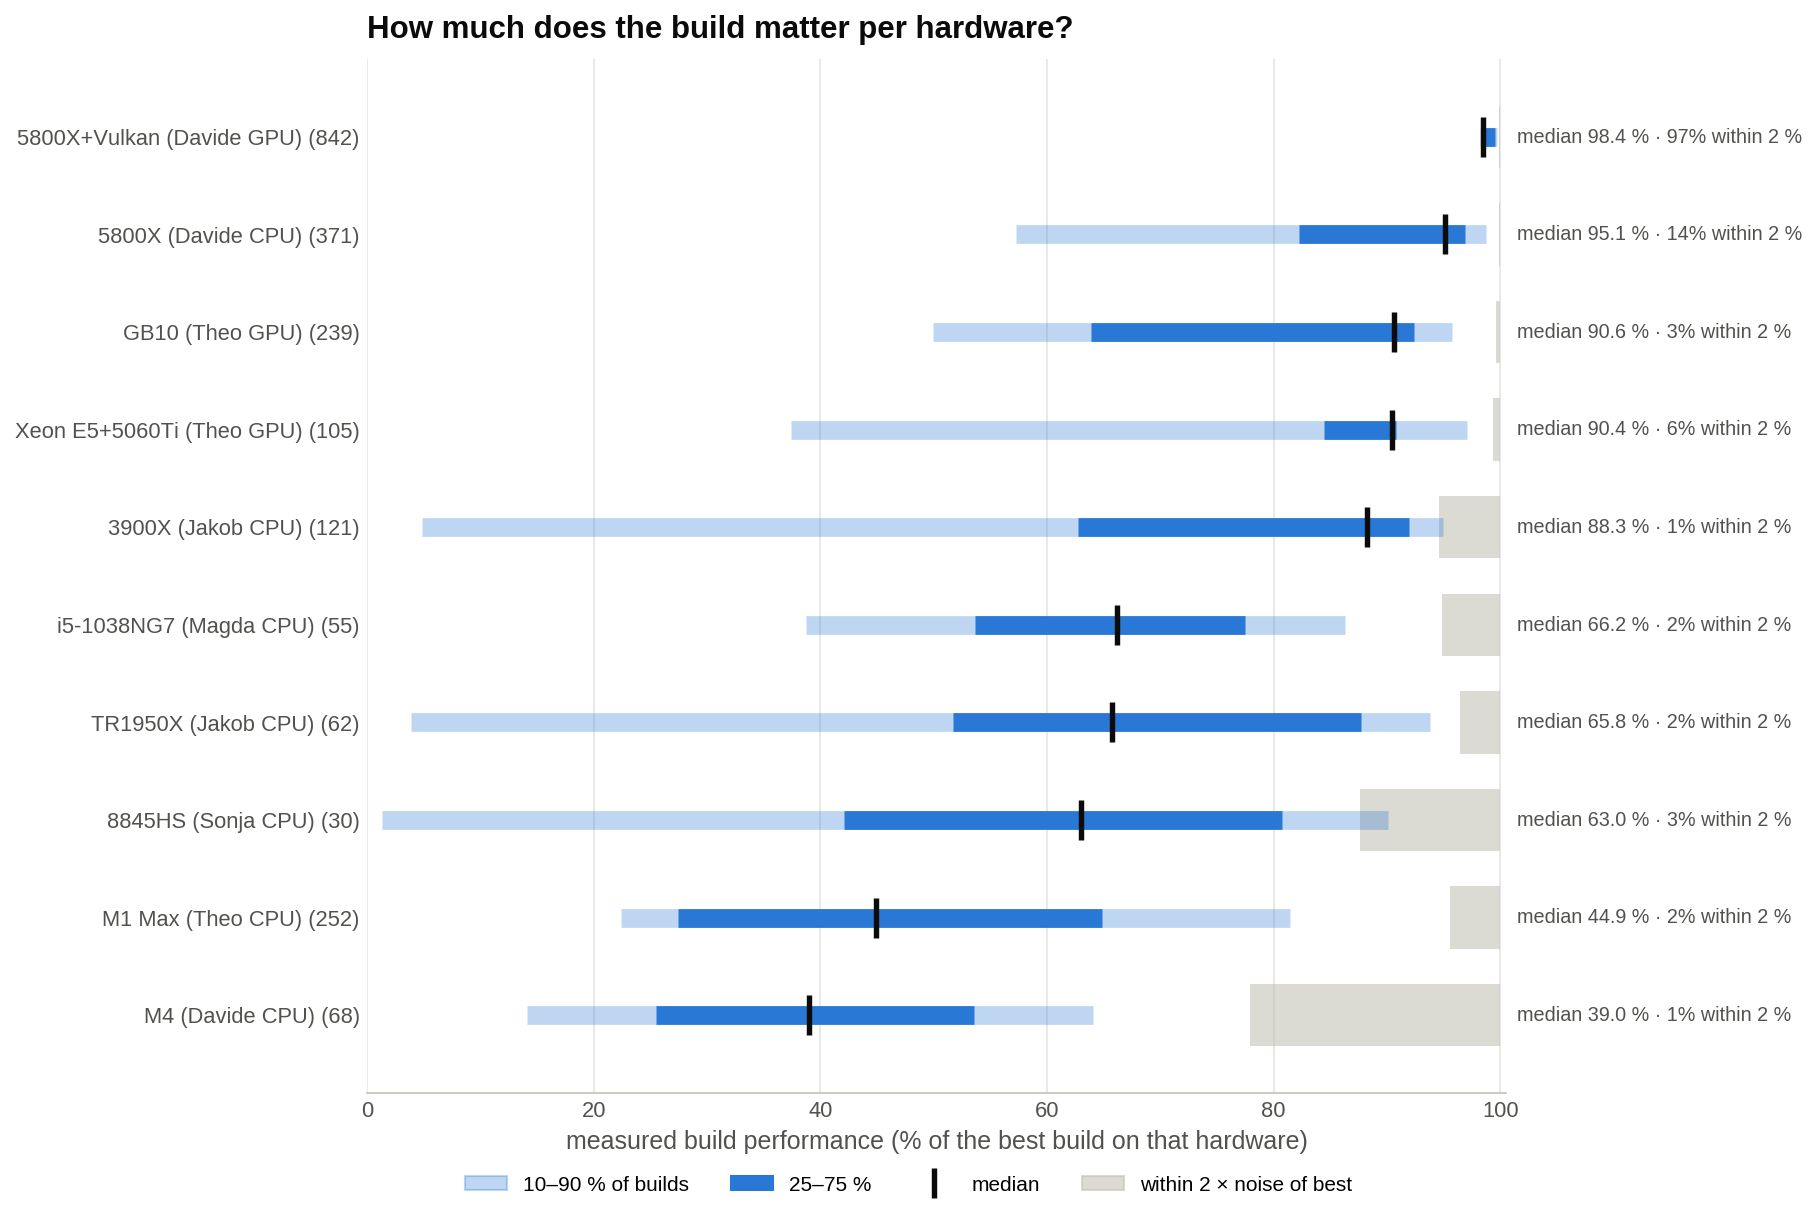

In [31]:
# Figure 1: spread of measured builds per hardware (bands: 10–90 % and 25–75 % of the builds)
order = spread.index.tolist()
fig, ax = plt.subplots(figsize=(12, 0.62 * len(order) + 1.8), layout="constrained")
for i, p in enumerate(order):
    q = np.percentile(pool.pct[pool.platform == p], [10, 25, 50, 75, 90])
    ax.add_patch(Rectangle((100 - 2 * spread.loc[p, "noise (%)"], i - 0.32), 2 * spread.loc[p, "noise (%)"], 0.64,
                           color=NEUTRAL, alpha=0.6, lw=0, zorder=1))
    ax.hlines(i, q[0], q[4], color=SERIES[0], lw=9, alpha=0.3, zorder=2)
    ax.hlines(i, q[1], q[3], color=SERIES[0], lw=9, zorder=3)
    ax.scatter(q[2], i, marker="|", s=380, color=INK, linewidth=2.6, zorder=4)
    if np.isfinite(spread.loc[p, "default build (%)"]):
        ax.scatter(spread.loc[p, "default build (%)"], i, marker="D", s=50, color=SURFACE, edgecolor=INK, lw=1.6, zorder=5)
    ax.text(1.01, i, f"median {spread.loc[p, 'median (%)']:.1f} % · {spread.loc[p, 'within 2 % of best']:.0%} within 2 %",
            transform=ax.get_yaxis_transform(), va="center", fontsize=9.5, color=INK2)
ax.set_yticks(range(len(order)), [f"{p} ({spread.loc[p, 'builds']})" for p in order])
ax.set_xlim(max(0, np.floor(pool.groupby("platform").pct.quantile(0.1).min() / 10) * 10 - 5), 100.5)
ax.spines["left"].set_visible(False)
style_axis(ax)
ax.set_xlabel("measured build performance (% of the best build on that hardware)")
handles = [Patch(color=SERIES[0], alpha=0.3, label="10–90 % of builds"), Patch(color=SERIES[0], label="25–75 %"),
           Line2D([], [], ls="", marker="|", ms=14, mew=2.6, color=INK, label="median"),
           Patch(color=NEUTRAL, alpha=0.6, label="within 2 × noise of best")]
if default_perf.size:
    handles.append(Line2D([], [], ls="", marker="D", mfc=SURFACE, mec=INK, label="default build"))
fig.legend(handles=handles, loc="outside lower center", ncol=5, frameon=False, fontsize=10)
ax.set_title("How much does the build matter per hardware?", **TITLE_STYLE)
plt.show()

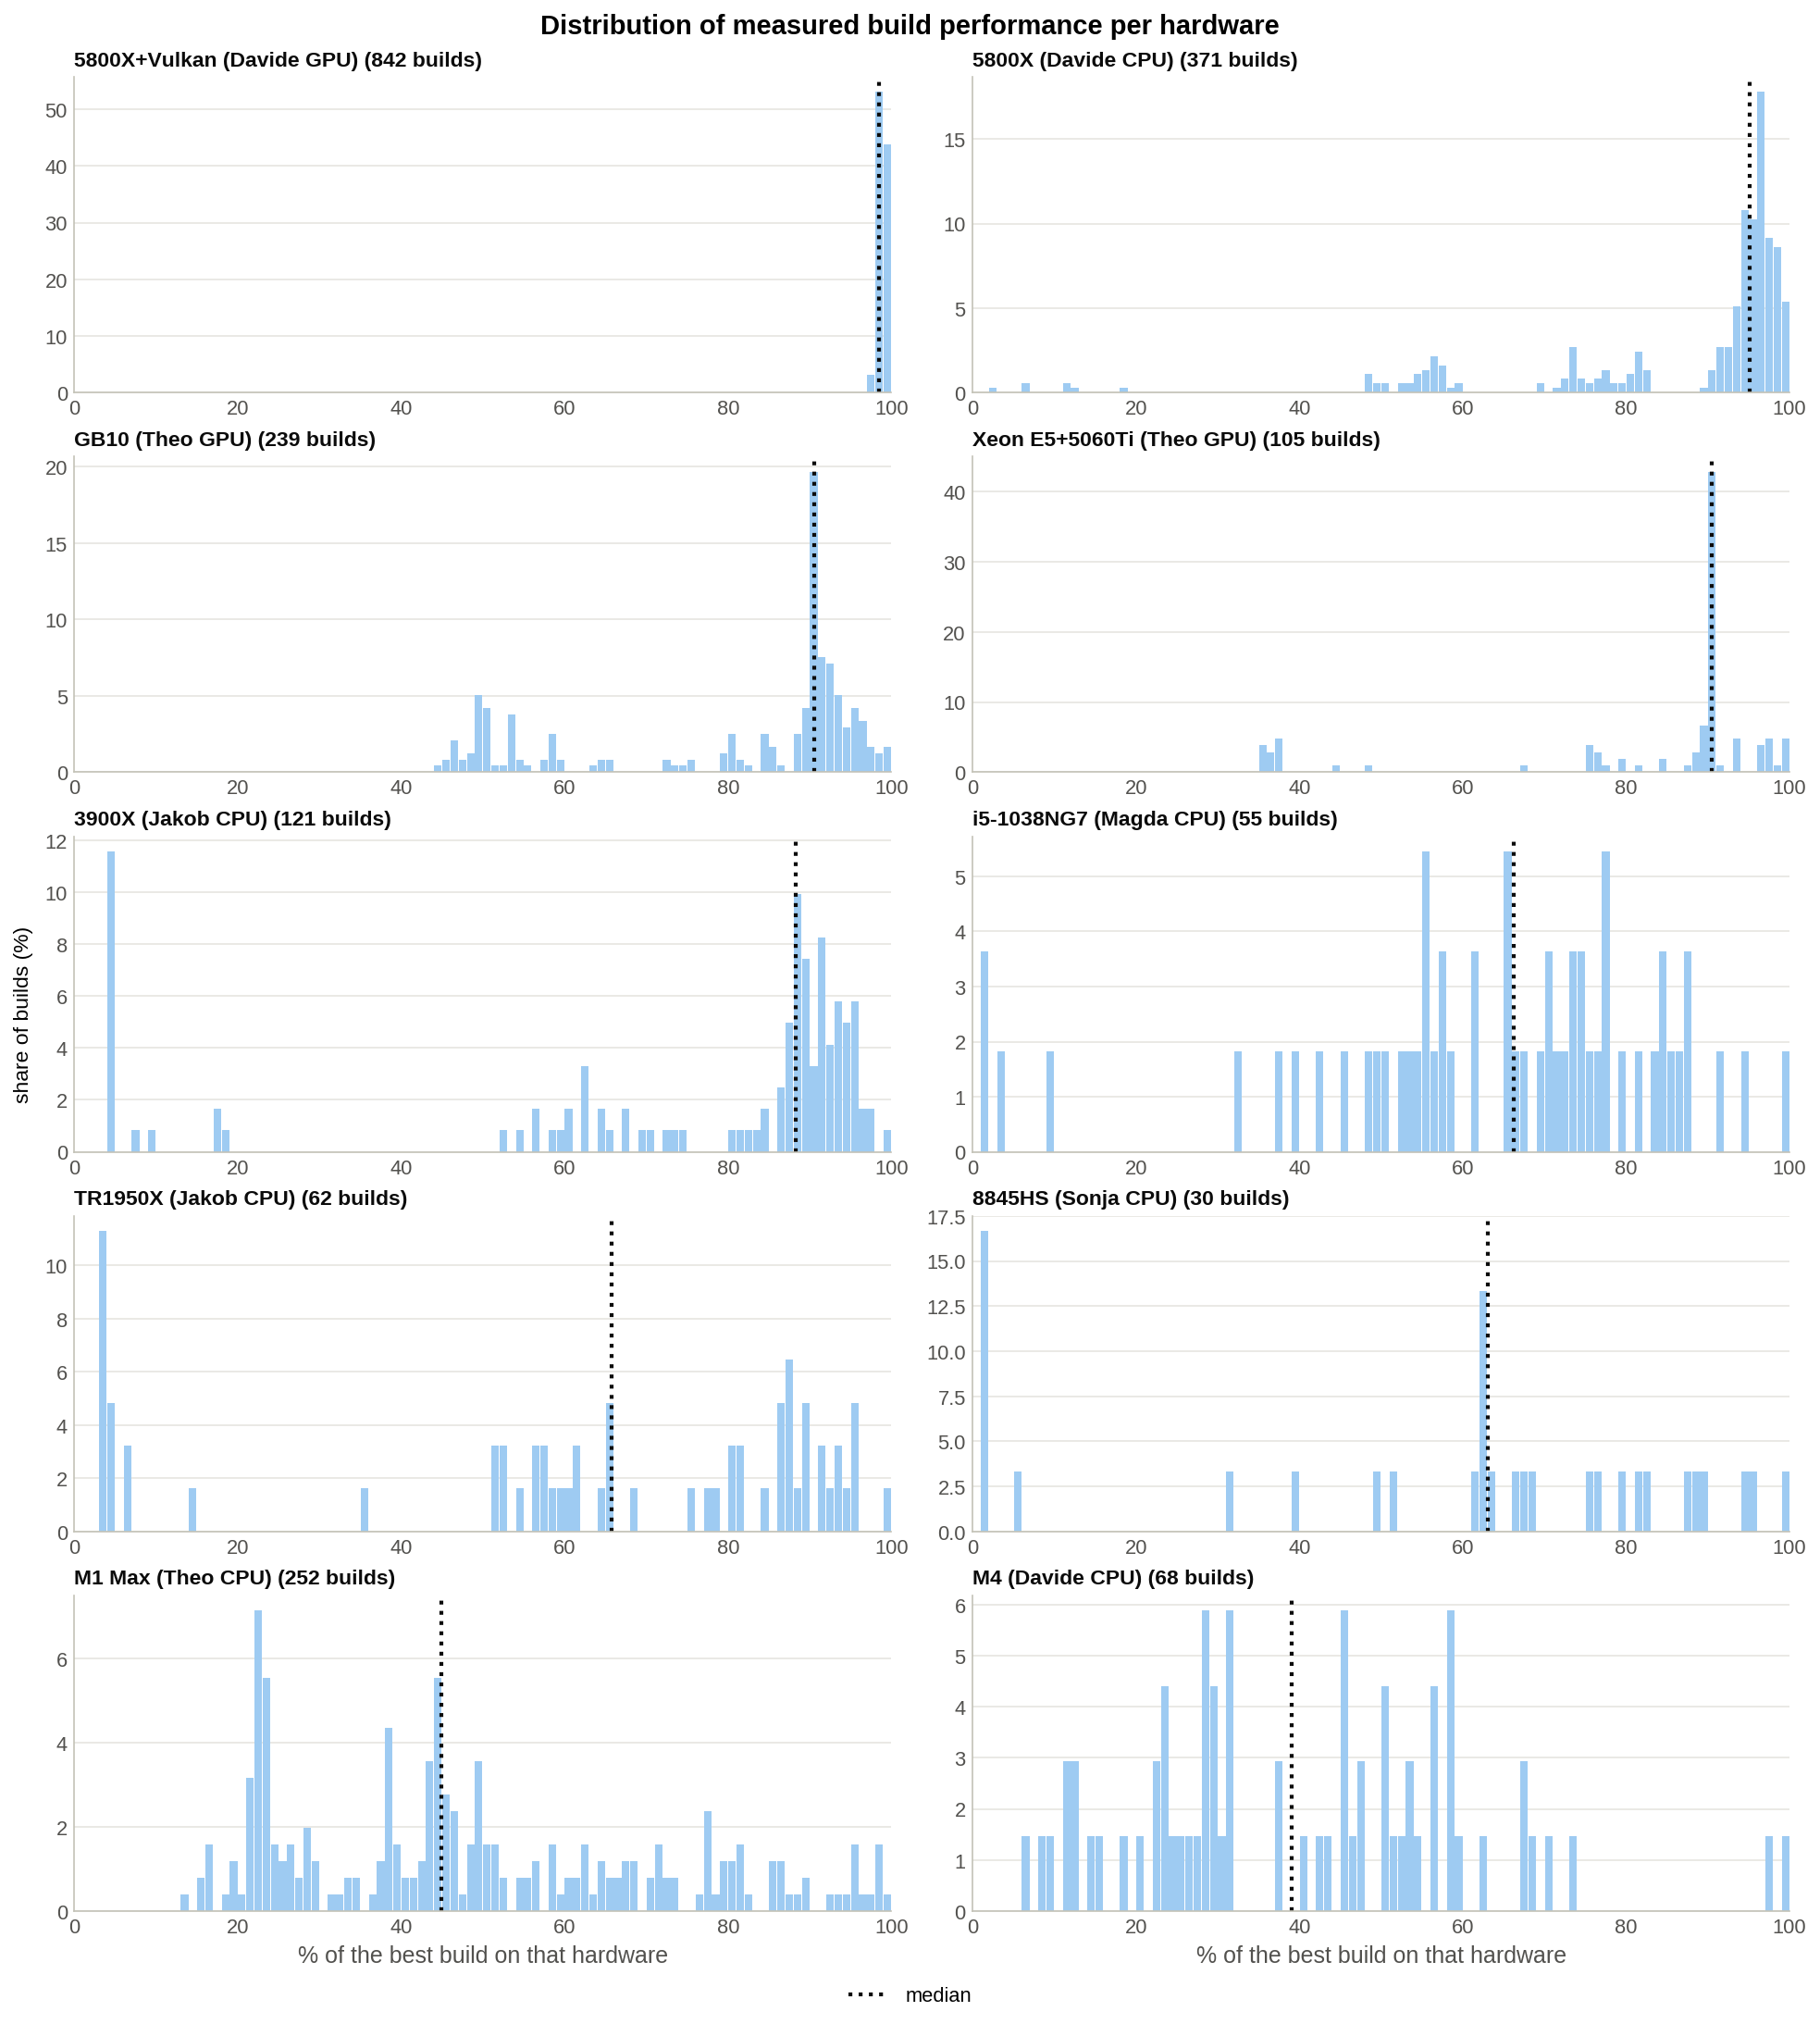

In [32]:
# Figure 2: histogram per hardware (x-axis always 0–100 %, 1 % bins; Figure 3 zooms in near the best)
cols = 2
rows_ = int(np.ceil(len(order) / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(13, 2.7 * rows_ + 1), layout="constrained", squeeze=False)
for ax, p in zip(axes.flat, order[::-1]):
    values = pool.pct[pool.platform == p]
    ax.hist(values, bins=np.linspace(0, 100, 101), weights=np.full(len(values), 100 / len(values)),
            color="#9ecbf2", rwidth=0.92)
    ax.set_xlim(0, 100)
    ax.axvline(values.median(), color=INK, ls=":", lw=2)
    if np.isfinite(spread.loc[p, "default build (%)"]):
        ax.axvline(spread.loc[p, "default build (%)"], color=BELOW, lw=2)
    ax.set_title(f"{p} ({len(values)} builds)", loc="left", fontsize=11, weight="bold")
    style_axis(ax, "y")
label_bottom(axes, len(order), "% of the best build on that hardware")
fig.supylabel("share of builds (%)", fontsize=11)
handles = [Line2D([], [], color=INK, ls=":", lw=2, label="median")]
if default_perf.size:
    handles.append(Line2D([], [], color=BELOW, lw=2, label="default build"))
fig.legend(handles=handles, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Distribution of measured build performance per hardware", fontsize=14, weight="bold")
plt.show()

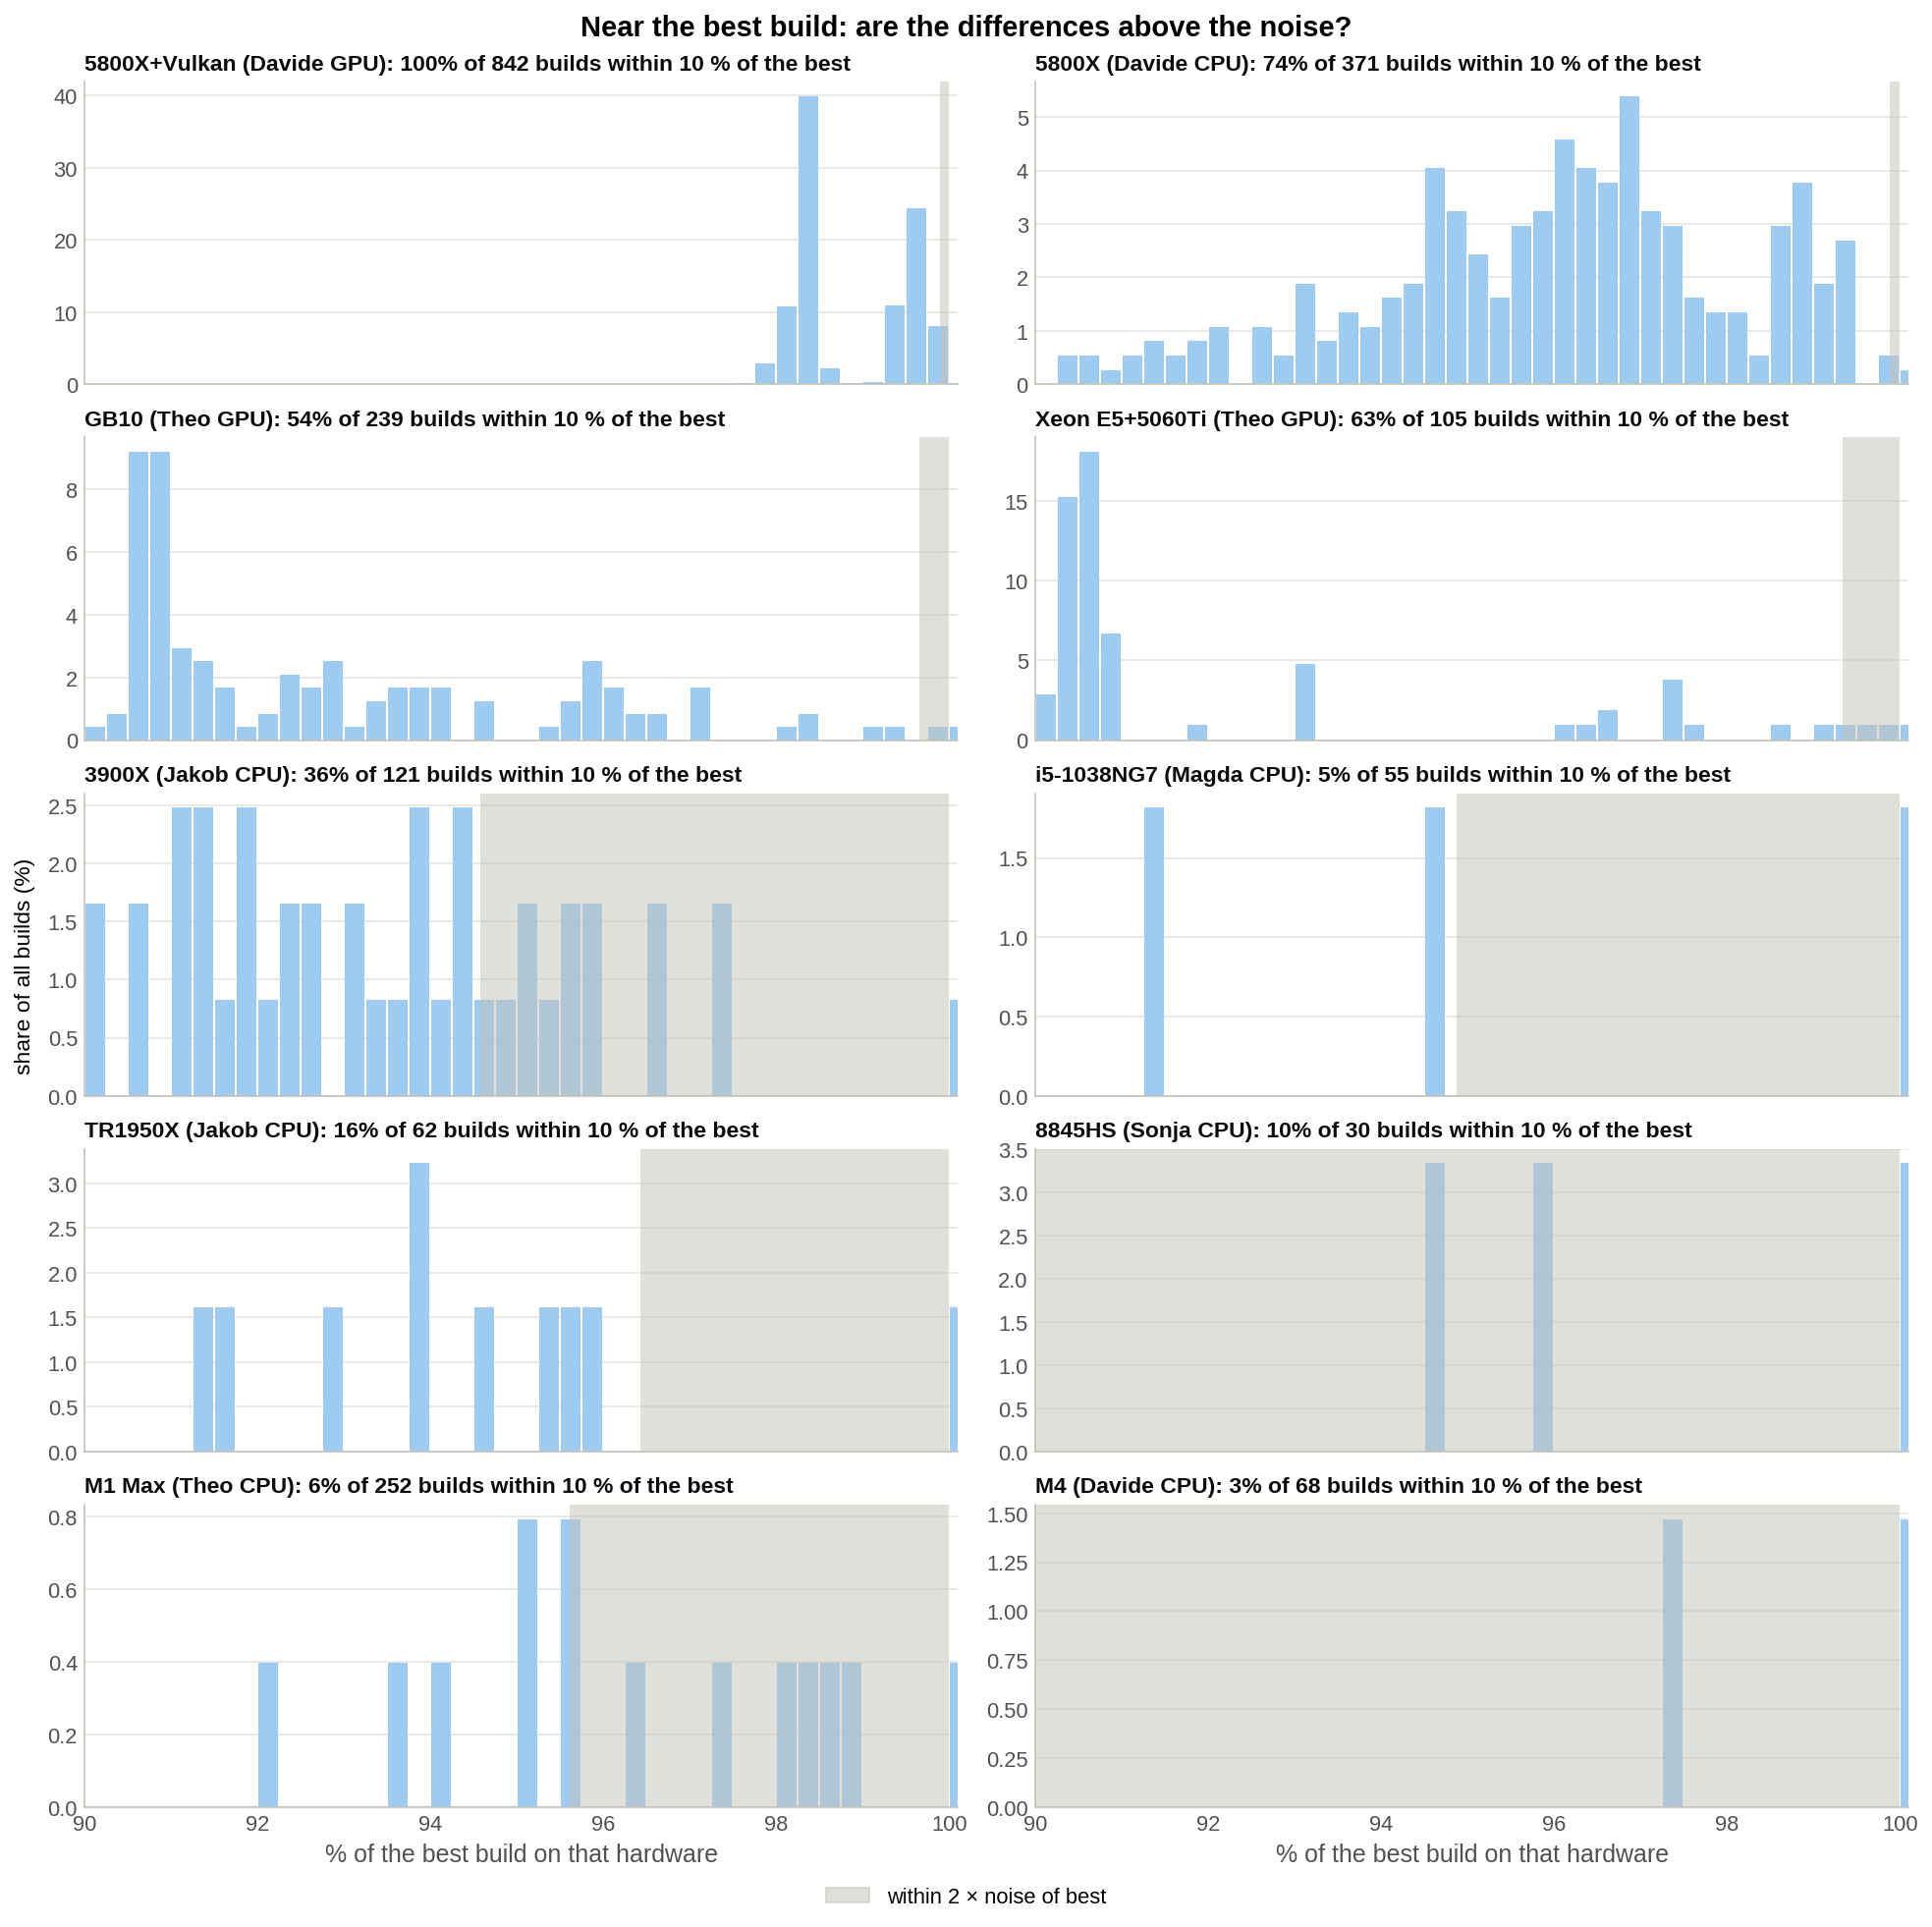

In [33]:
# Figure 3: zoom on the builds within 10 % of the best (same x-axis for every hardware; bars = share of all builds)
ZOOM = 90
fig, axes = plt.subplots(rows_, cols, figsize=(13, 2.4 * rows_ + 1), sharex=True, layout="constrained", squeeze=False)
for ax, p in zip(axes.flat, order[::-1]):
    values = pool.pct[pool.platform == p]
    near = values[values >= ZOOM]
    ax.hist(near, bins=np.arange(ZOOM, 100.26, 0.25), weights=np.full(len(near), 100 / len(values)),
            color="#9ecbf2", rwidth=0.92)
    ax.axvspan(100 - 2 * spread.loc[p, "noise (%)"], 100, color=NEUTRAL, alpha=0.5, lw=0)
    if np.isfinite(spread.loc[p, "default build (%)"]):
        ax.axvline(spread.loc[p, "default build (%)"], color=BELOW, lw=2)
    ax.set_title(f"{p}: {len(near) / len(values):.0%} of {len(values)} builds within {100 - ZOOM} % of the best",
                 loc="left", fontsize=11, weight="bold")
    style_axis(ax, "y")
label_bottom(axes, len(order), "% of the best build on that hardware")
axes[0, 0].set_xlim(ZOOM, 100.1)
fig.supylabel("share of all builds (%)", fontsize=11)
handles = [Patch(color=NEUTRAL, alpha=0.5, label="within 2 × noise of best")]
if default_perf.size:
    handles.append(Line2D([], [], color=BELOW, lw=2, label="default build"))
fig.legend(handles=handles, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"Near the best build: are the differences above the noise?", fontsize=14, weight="bold")
plt.show()

## 2. Sessions

- **Sessions** (`RESULTS`): one row per attempt. *Simulated* sessions replay a pool, so their reference is the pool's best build. *Live* sessions have no pool, so their reference is the best build known for that hardware (pool or any live session).
- Hardware/no-hardware twins of a local model are identical on one machine: they get one name (`no-hardware-X` → `X`, the ridge models → `ridge` / `ridge-pairs`) and duplicate simulated sessions are dropped.

In [34]:
# Sessions
timings = evaluation_tables(RESULTS, "timings")
timings = timings[timings.application == APP].copy()
timings["platform"] = timings.platform.map(short)
timings["live"] = timings.groupby(KEY).pool_best_performance.transform(lambda s: s.isna().all())
if MODE is not None:
    timings = timings[timings.live == (MODE == "live")]
timings = timings.sort_values(KEY + ["step"]).reset_index(drop=True)
timings["model_seconds"] = timings[["next_sample_seconds", "refit_seconds", "prediction_seconds"]].fillna(0).sum(axis=1)

sessions = timings[timings.step <= BUDGET].groupby(KEY, sort=False).agg(
    live=("live", "first"), first=("step", "min"), last=("step", "max"), pool_best=("pool_best_performance", "first"),
    found=("best_observed_performance", "max"), init_seconds=("initialization_seconds", "first"),
    model_seconds=("model_seconds", "sum"), failed=("attempt_status", lambda s: int((s == "failed").sum()))).reset_index()
sessions["model_seconds"] += sessions.init_seconds.fillna(0)
sessions["historical"] = sessions.pretrained.replace("none", COLD)
sessions["local"] = sessions.model.map(local_family)
FIRST = int(sessions["first"].mode()[0])          # first step after the start builds
STEPS = list(range(FIRST, BUDGET + 1))

simulated = sessions[~sessions.live]
duplicate = simulated.duplicated(["platform", *PAIR, "seed"], keep=False).reindex(sessions.index, fill_value=False)
if duplicate.any():
    spread_ = sessions[duplicate].groupby(["platform", *PAIR, "seed"]).found.agg(lambda s: s.max() / s.min() - 1)
    print(f"duplicate simulated sessions (twins / repeated runs): largest difference in the best build found {spread_.max():.2g}")
dropped = {"fewer than BUDGET builds": sessions["last"] < BUDGET,
           "other number of start builds": sessions["first"] != FIRST,
           "duplicate simulated session": simulated.duplicated(["platform", *PAIR, "seed"]).reindex(sessions.index, fill_value=False)}
for reason, mask in dropped.items():
    if mask.any():
        print(f"left out {mask.sum()} sessions: {reason}")
sessions = sessions[~np.logical_or.reduce(list(dropped.values()))].reset_index(drop=True)
sessions["sid"] = sessions.index
timings = timings.merge(sessions[KEY + ["sid"]], on=KEY)

# Reference = 100 %: pool best (simulated) or best build known on that hardware (live)
pool_best = pool.groupby("platform").performance.max()
best_known = pd.concat([pool_best, sessions[sessions.live].groupby("platform").found.max()], axis=1).max(axis=1)
sessions["reference"] = np.where(sessions.live, sessions.platform.map(best_known), sessions.pool_best)
found = (timings.pivot_table(index="sid", columns="step", values="best_observed_performance", aggfunc="first")
         .reindex(index=sessions.sid, columns=STEPS).ffill(axis=1))          # best performance found so far
best_pct = (100 * found.div(sessions.reference.to_numpy(), axis=0)).fillna(0)
sessions["auc"] = best_pct.mean(axis=1).to_numpy()

simulated_best = sessions[~sessions.live].groupby("platform").pool_best.first()
off = simulated_best[(simulated_best / pool_best.reindex(simulated_best.index) - 1).abs().fillna(1) > 1e-6]
if len(off):
    print("WARNING: DATA is not the pool the simulation replayed on", list(off.index),
          "→ random baseline, distributions, default build and build times use DATA")

PLATFORMS = sorted(sessions.platform.unique())
ON_PLATFORMS = f"{len(PLATFORMS)} platform" + ("s" if len(PLATFORMS) != 1 else "")
overview = pd.DataFrame({
    "builds": pool.groupby("platform").size(),
    f"best ({UNIT})": pool_best,
    "simulated sessions": sessions[~sessions.live].groupby("platform").size(),
    "live sessions": sessions[sessions.live].groupby("platform").size(),
    "pairs": sessions.groupby("platform")[PAIR].apply(lambda f: len(f.drop_duplicates())),
    "seeds / repeats": sessions.groupby(["platform", *PAIR]).size().groupby("platform").max(),
}).reindex(PLATFORMS).fillna(0).astype({"simulated sessions": int, "live sessions": int, "pairs": int, "seeds / repeats": int})
display(overview)

duplicate simulated sessions (twins / repeated runs): largest difference in the best build found 0.034
left out 2070 sessions: duplicate simulated session


,builds,best (tokens/s),simulated sessions,live sessions,pairs,seeds / repeats
platform,,,,,,
3900X (Jakob CPU),121,56.39,256,0,232,3
5800X (Davide CPU),371,68.50,256,0,232,3
5800X+Vulkan (Davide GPU),842,411.98,256,0,232,3
8845HS (Sonja CPU),30,77.68,256,0,232,3
GB10 (Theo GPU),239,480.90,256,0,232,3
M1 Max (Theo CPU),252,143.07,256,0,232,3
M4 (Davide CPU),68,69.51,256,0,232,3
TR1950X (Jakob CPU),62,53.51,256,0,232,3
Xeon E5+5060Ti (Theo GPU),105,790.51,256,0,232,3


## 3. Baselines per hardware

- **Random:** exact expected best-so-far of uniform random picks from the pool (no seeds, no noise). For live sessions the pool stands in for the flag space.
- **Median build:** a typical untuned build. **Default build:** `DEFAULT_BUILD` looked up in the pool (shown once it is set).

In [35]:
random_curve = pd.DataFrame({p: 100 * expected_best(pool.performance[pool.platform == p], STEPS)
                             / sessions.reference[sessions.platform == p].max() for p in PLATFORMS
                             if (pool.platform == p).any()}, index=STEPS).T
random_auc = random_curve.mean(axis=1)



reference = sessions.groupby("platform").reference.max()
median_perf = pool.groupby("platform").performance.median()
baselines = pd.DataFrame({"random AUC": random_auc,
                          "median build (%)": 100 * median_perf / reference,
                          "default build (%)": 100 * default_perf / reference}).reindex(PLATFORMS)
if baselines["default build (%)"].isna().any():
    print("default build:", "not set" if not DEFAULT_BUILD else
          f"not measured on {list(baselines.index[baselines['default build (%)'].isna()])}")
display(baselines.style.format(precision=2, na_rep="–"))

default build: not set


,random AUC,median build (%),default build (%)
3900X (Jakob CPU),95.80,88.28,–
5800X (Davide CPU),98.73,95.12,–
5800X+Vulkan (Davide GPU),99.74,98.44,–
8845HS (Sonja CPU),94.93,63.02,–
GB10 (Theo GPU),96.49,90.61,–
M1 Max (Theo CPU),87.70,44.89,–
M4 (Davide CPU),76.95,39.02,–
TR1950X (Jakob CPU),94.60,65.77,–
Xeon E5+5060Ti (Theo GPU),97.47,90.42,–
i5-1038NG7 (Magda CPU),90.65,66.20,–


## 4. Ranking of all pairs by AUC

- **AUC** = mean of best-build-so-far (% of the reference) over steps 3–25: 100 means the best build was found right after the start builds. Early finds count more than late ones.
- Per pair: mean over seeds (repeats) per hardware, then mean over hardware. The thick bar is the **range over seeds** (spread of the hardware mean, seed by seed); the thin line the **95 % bootstrap interval over hardware** (resampling the platforms; computed for Δ vs. random and drawn around the AUC and capped at 100, so it shows how stable the ranking is, not how different the platforms are).
- The table also shows `best@10` / `best@25`: the best build found after 10 / 25 builds.
- The order is that of **AUC − random AUC on the same hardware**: identical to ordering by AUC when every pair ran on every hardware, and still fair when (live) pairs cover different hardware.

In [36]:
sessions["delta"] = sessions.auc - sessions.platform.map(random_auc)
BEST_AT = [f"best@{n}" for n in dict.fromkeys([10, BUDGET]) if n in STEPS]
for name in BEST_AT:
    sessions[name] = best_pct[int(name.split("@")[1])].to_numpy()
cell = sessions.groupby([*PAIR, "platform"])[["auc", "delta", *BEST_AT]].mean()
sessions["rep"] = sessions.sort_values(["seed", "run"]).groupby([*PAIR, "platform"]).cumcount()
sessions["dev"] = sessions.auc - sessions.groupby([*PAIR, "platform"]).auc.transform("mean")
rep_dev = sessions.groupby([*PAIR, "rep"]).dev.mean()

ranking = cell.groupby(PAIR).mean()
ranking["low"] = ranking.auc + rep_dev.groupby(PAIR).min()
ranking["high"] = ranking.auc + rep_dev.groupby(PAIR).max()
ranking["platforms"] = cell.groupby(PAIR).size()
ranking["seeds"] = sessions.groupby(PAIR).rep.nunique()
ranking["model s / session"] = sessions.groupby(PAIR).model_seconds.mean()
ranking = ranking.sort_values("delta" if ranking.delta.notna().all() else "auc", ascending=False)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))

# 95 % bootstrap interval over hardware (resampling the platforms, 2000×) of Δ vs random, drawn around the AUC
delta_by_platform = cell.delta.unstack("platform").reindex(index=ranking.index, columns=PLATFORMS)
draws = np.random.default_rng(0).integers(0, len(PLATFORMS), size=(2000, len(PLATFORMS)))
warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN rows (pairs without a random baseline) stay NaN
boot = np.stack([np.nanmean(delta_by_platform.to_numpy()[:, d], axis=1) for d in draws])
ranking["Δ low"], ranking["Δ high"] = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)

candidates = ranking.drop(index=[RANDOM_PAIR], errors="ignore")
if ONE_PER_HISTORICAL:
    candidates = candidates.groupby(level="historical", sort=False).head(1)
TOP = candidates.head(TOP_N).index.tolist()
RANDOM_AUC = random_auc.reindex(PLATFORMS).mean()
DEFAULT_PCT = baselines["default build (%)"].mean()   # NaN until a default build is set and measured

# Line style per top pair: colour + dash by rank (at most 8 colours stay distinguishable, so 10 pairs = 5 colours × 2 dashes)
DASHES = ["-", (0, (5, 2)), (0, (1.2, 1.8)), (0, (7, 2, 1.5, 2))]
n_dashes = int(np.ceil(len(TOP) / len(SERIES)))
n_colours = int(np.ceil(len(TOP) / n_dashes)) if TOP else 1
STYLE = {pair: dict(color=SERIES[i % n_colours], ls=DASHES[min(i // n_colours, len(DASHES) - 1)])
         for i, pair in enumerate(TOP)}
hist_order, local_order = list(dict.fromkeys(h for h, _ in TOP)), list(dict.fromkeys(l for _, l in TOP))

table = ranking[["rank", "auc", *BEST_AT, "low", "high", "delta", "Δ low", "Δ high", "platforms", "seeds", "model s / session"]].rename(
    columns={"auc": "AUC", "low": "AUC seed min", "high": "AUC seed max", "delta": "Δ vs random",
             "Δ low": "Δ 95 % low", "Δ high": "Δ 95 % high"})
display(table.head(max(15, TOP_N)).style.format(precision=2).apply(
    lambda row: ["font-weight: bold" if row.name in TOP else ""] * len(row), axis=1))

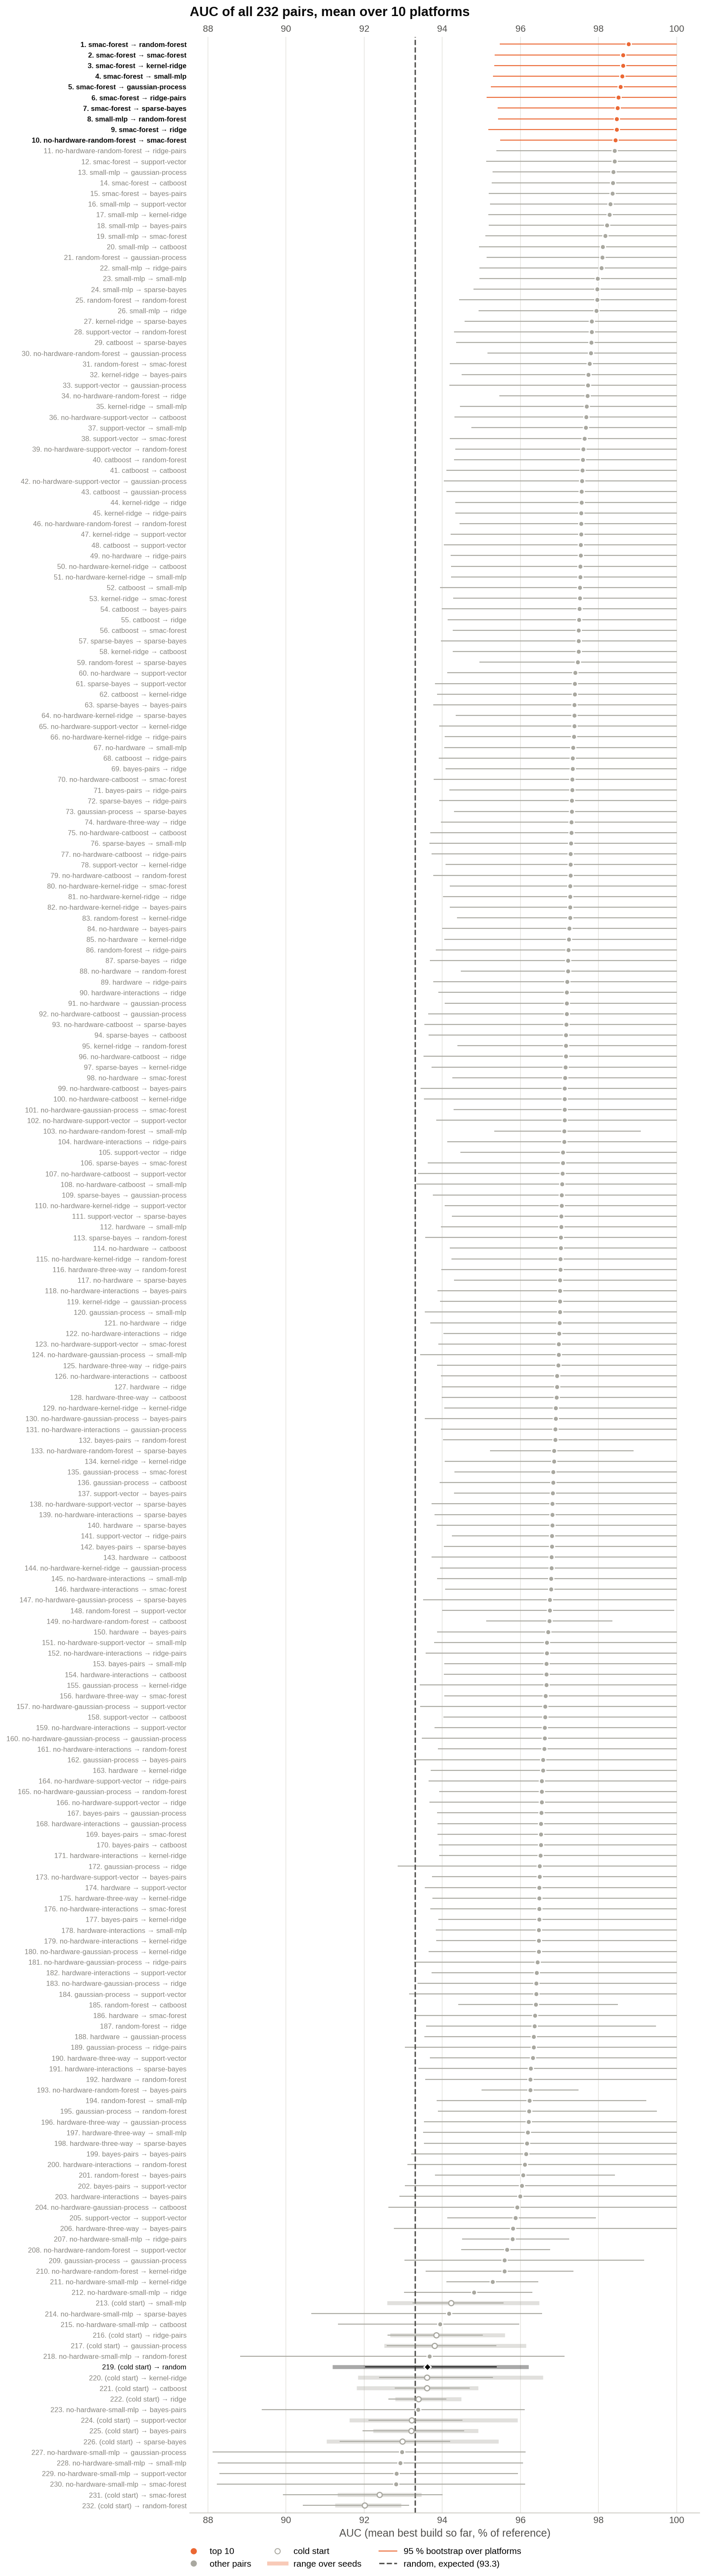

In [37]:
# Figure 4: AUC of all pairs (top pairs highlighted)
rows = ranking.index.tolist()
y = {pair: len(rows) - 1 - i for i, pair in enumerate(rows)}
kind = {pair: "top" if pair in TOP else "random" if pair == RANDOM_PAIR else "cold" if pair[0] == COLD else "other"
        for pair in rows}
colour = {"top": ACCENT, "random": INK, "cold": OTHER, "other": OTHER}
fig, ax = plt.subplots(figsize=(11, 0.165 * len(rows) + 2.2), layout="constrained")
for pair in rows:
    r = ranking.loc[pair]
    ax.hlines(y[pair], r.auc + r["Δ low"] - r.delta, min(100, r.auc + r["Δ high"] - r.delta),
              color=colour[kind[pair]], lw=1.1, zorder=2)
    ax.hlines(y[pair], r.low, r.high, color=colour[kind[pair]], lw=4.5, alpha=0.35, zorder=3)
    filled = kind[pair] != "cold"
    ax.scatter(r.auc, y[pair], s=34, marker="D" if kind[pair] == "random" else "o", zorder=4,
               color=colour[kind[pair]] if filled else SURFACE, edgecolor=colour[kind[pair]] if not filled else SURFACE,
               linewidth=1.3)
ax.axvline(RANDOM_AUC, color=INK2, ls="--", lw=1.6)
if np.isfinite(DEFAULT_PCT):
    ax.axvline(DEFAULT_PCT, color=INK, ls=":", lw=1.8)
ax.set_yticks([y[p] for p in rows], [f"{int(ranking.loc[p, 'rank'])}. {label(p)}" for p in rows], fontsize=8)
for tick, pair in zip(ax.get_yticklabels(), rows):
    tick.set_color(INK if kind[pair] in ("top", "random") else MUTED)
    tick.set_fontweight("bold" if kind[pair] == "top" else "normal")
ax.set_ylim(-0.7, len(rows) - 0.3)
ax.spines["left"].set_visible(False)
style_axis(ax)
ax.xaxis.set_tick_params(labeltop=True)
ax.set_xlabel("AUC (mean best build so far, % of reference)")
handles = [Line2D([], [], ls="", marker="o", ms=6, color=ACCENT, label=f"top {len(TOP)}"),
           Line2D([], [], ls="", marker="o", ms=6, color=OTHER, label="other pairs"),
           Line2D([], [], ls="", marker="o", ms=6, mfc=SURFACE, mec=OTHER, label="cold start"),
           Line2D([], [], color=ACCENT, lw=4.5, alpha=0.35, label="range over seeds"),
           Line2D([], [], color=ACCENT, lw=1.1, label="95 % bootstrap over platforms"),
           Line2D([], [], color=INK2, ls="--", lw=1.6, label=f"random, expected ({RANDOM_AUC:.1f})")]
if np.isfinite(DEFAULT_PCT):
    handles.append(Line2D([], [], color=INK, ls=":", lw=1.8, label=f"default build ({DEFAULT_PCT:.1f})"))
fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False, fontsize=10)
ax.set_title(f"AUC of all {len(rows)} pairs, mean over {ON_PLATFORMS}", **TITLE_STYLE)
plt.show()

## 5. Top pairs: best build found so far

Mean over hardware of the best build found after each step. Grey band: range over the cold-start local models (no historical model). The lower panel shows the same curves minus random, to separate lines that overlap above.

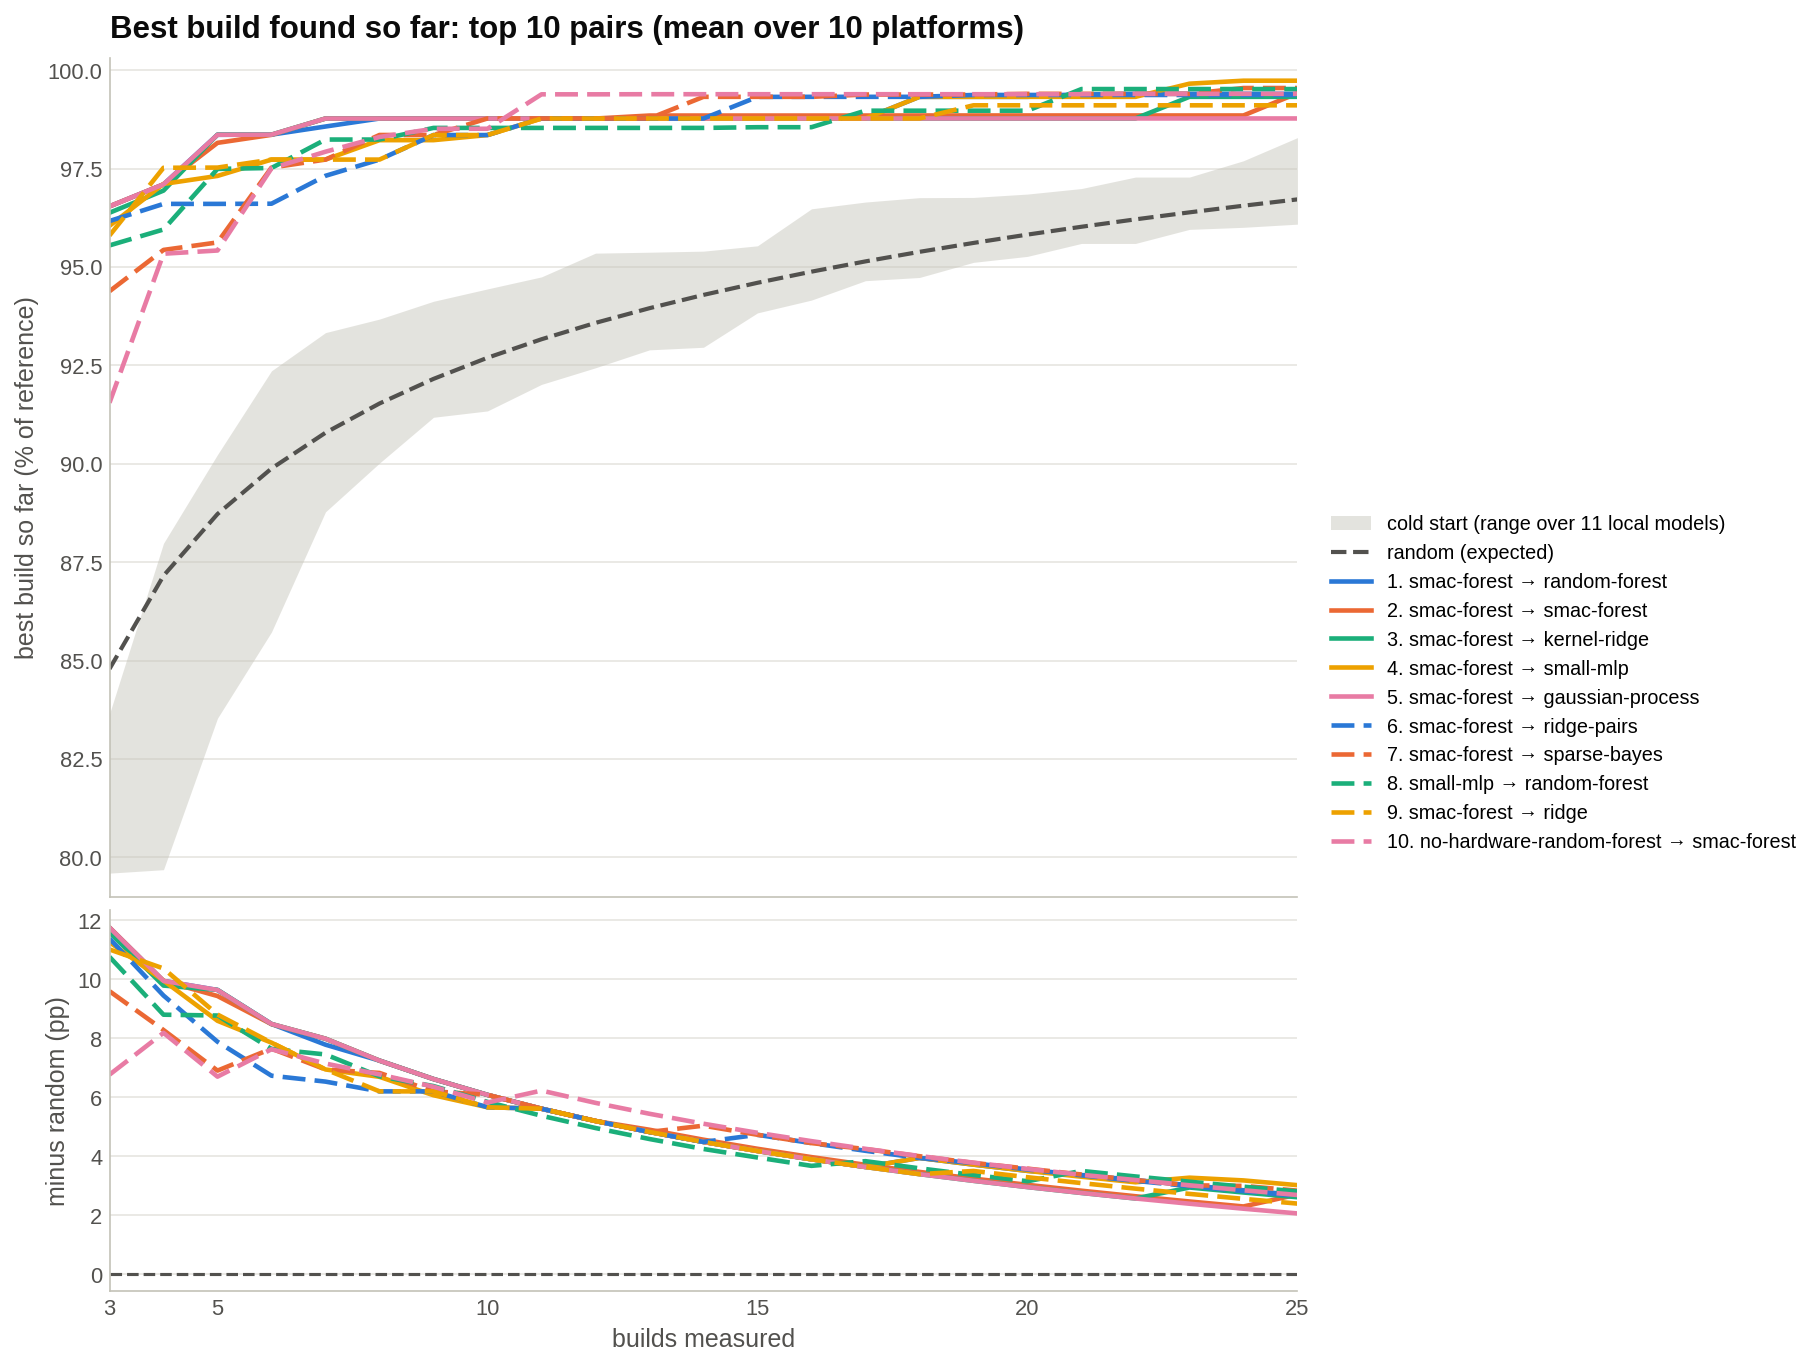

In [38]:
# Figure 5: best build found so far, top pairs vs. random, cold start and default build
def curve(mask):
    frame = best_pct[mask.to_numpy()]
    return frame.groupby(sessions.platform[mask].to_numpy()).mean().mean()


def pair_mask(pair):
    return (sessions.historical == pair[0]) & (sessions.local == pair[1])


random_line = random_curve.reindex(PLATFORMS).mean()
cold_locals = [l for l in sessions.local[sessions.historical == COLD].unique() if l != "random"]
cold = pd.DataFrame({l: curve(pair_mask((COLD, l))) for l in cold_locals}).T
fig, (top, gap) = plt.subplots(2, 1, figsize=(12, 9), sharex=True, layout="constrained",
                               gridspec_kw=dict(height_ratios=[2.2, 1]))
if len(cold):
    top.fill_between(STEPS, cold.min(), cold.max(), color=NEUTRAL, alpha=0.45, lw=0,
                     label=f"cold start (range over {len(cold)} local models)")
top.plot(STEPS, random_line, color=INK2, ls="--", lw=2, label="random (expected)")
if np.isfinite(DEFAULT_PCT):
    top.axhline(DEFAULT_PCT, color=INK, ls=":", lw=2, label="default build")
lowest = [random_line.min(), cold.min().min() if len(cold) else np.nan, DEFAULT_PCT]
for rank, pair in enumerate(TOP, 1):
    values = curve(pair_mask(pair))
    style = dict(**STYLE[pair], lw=2.2)
    top.plot(STEPS, values, label=f"{rank}. {label(pair)}", **style)
    gap.plot(STEPS, values - random_line, **style)
    lowest.append(values.min())
gap.axhline(0, color=INK2, ls="--", lw=1.5)
top.set_ylim(max(np.floor(np.nanmin(lowest) - 0.5), 0) if np.isfinite(lowest).any() else 0, 100.3)
top.set_ylabel("best build so far (% of reference)")
gap.set_ylabel("minus random (pp)")
gap.set_xlabel("builds measured")
gap.set_xlim(STEPS[0], STEPS[-1])
gap.set_xticks([STEPS[0], *range(5, BUDGET + 1, 5)])
for ax in (top, gap):
    style_axis(ax, "y")
fig.legend(*top.get_legend_handles_labels(), loc="outside right center", frameon=False, fontsize=9.5)
top.set_title(f"Best build found so far: top {len(TOP)} pairs (mean over {ON_PLATFORMS})", **TITLE_STYLE)
plt.show()

## 6. All pairs as a grid

AUC per historical (rows) × local model (columns); the cold-start row has no historical model. White frames with bold values mark the top pairs.

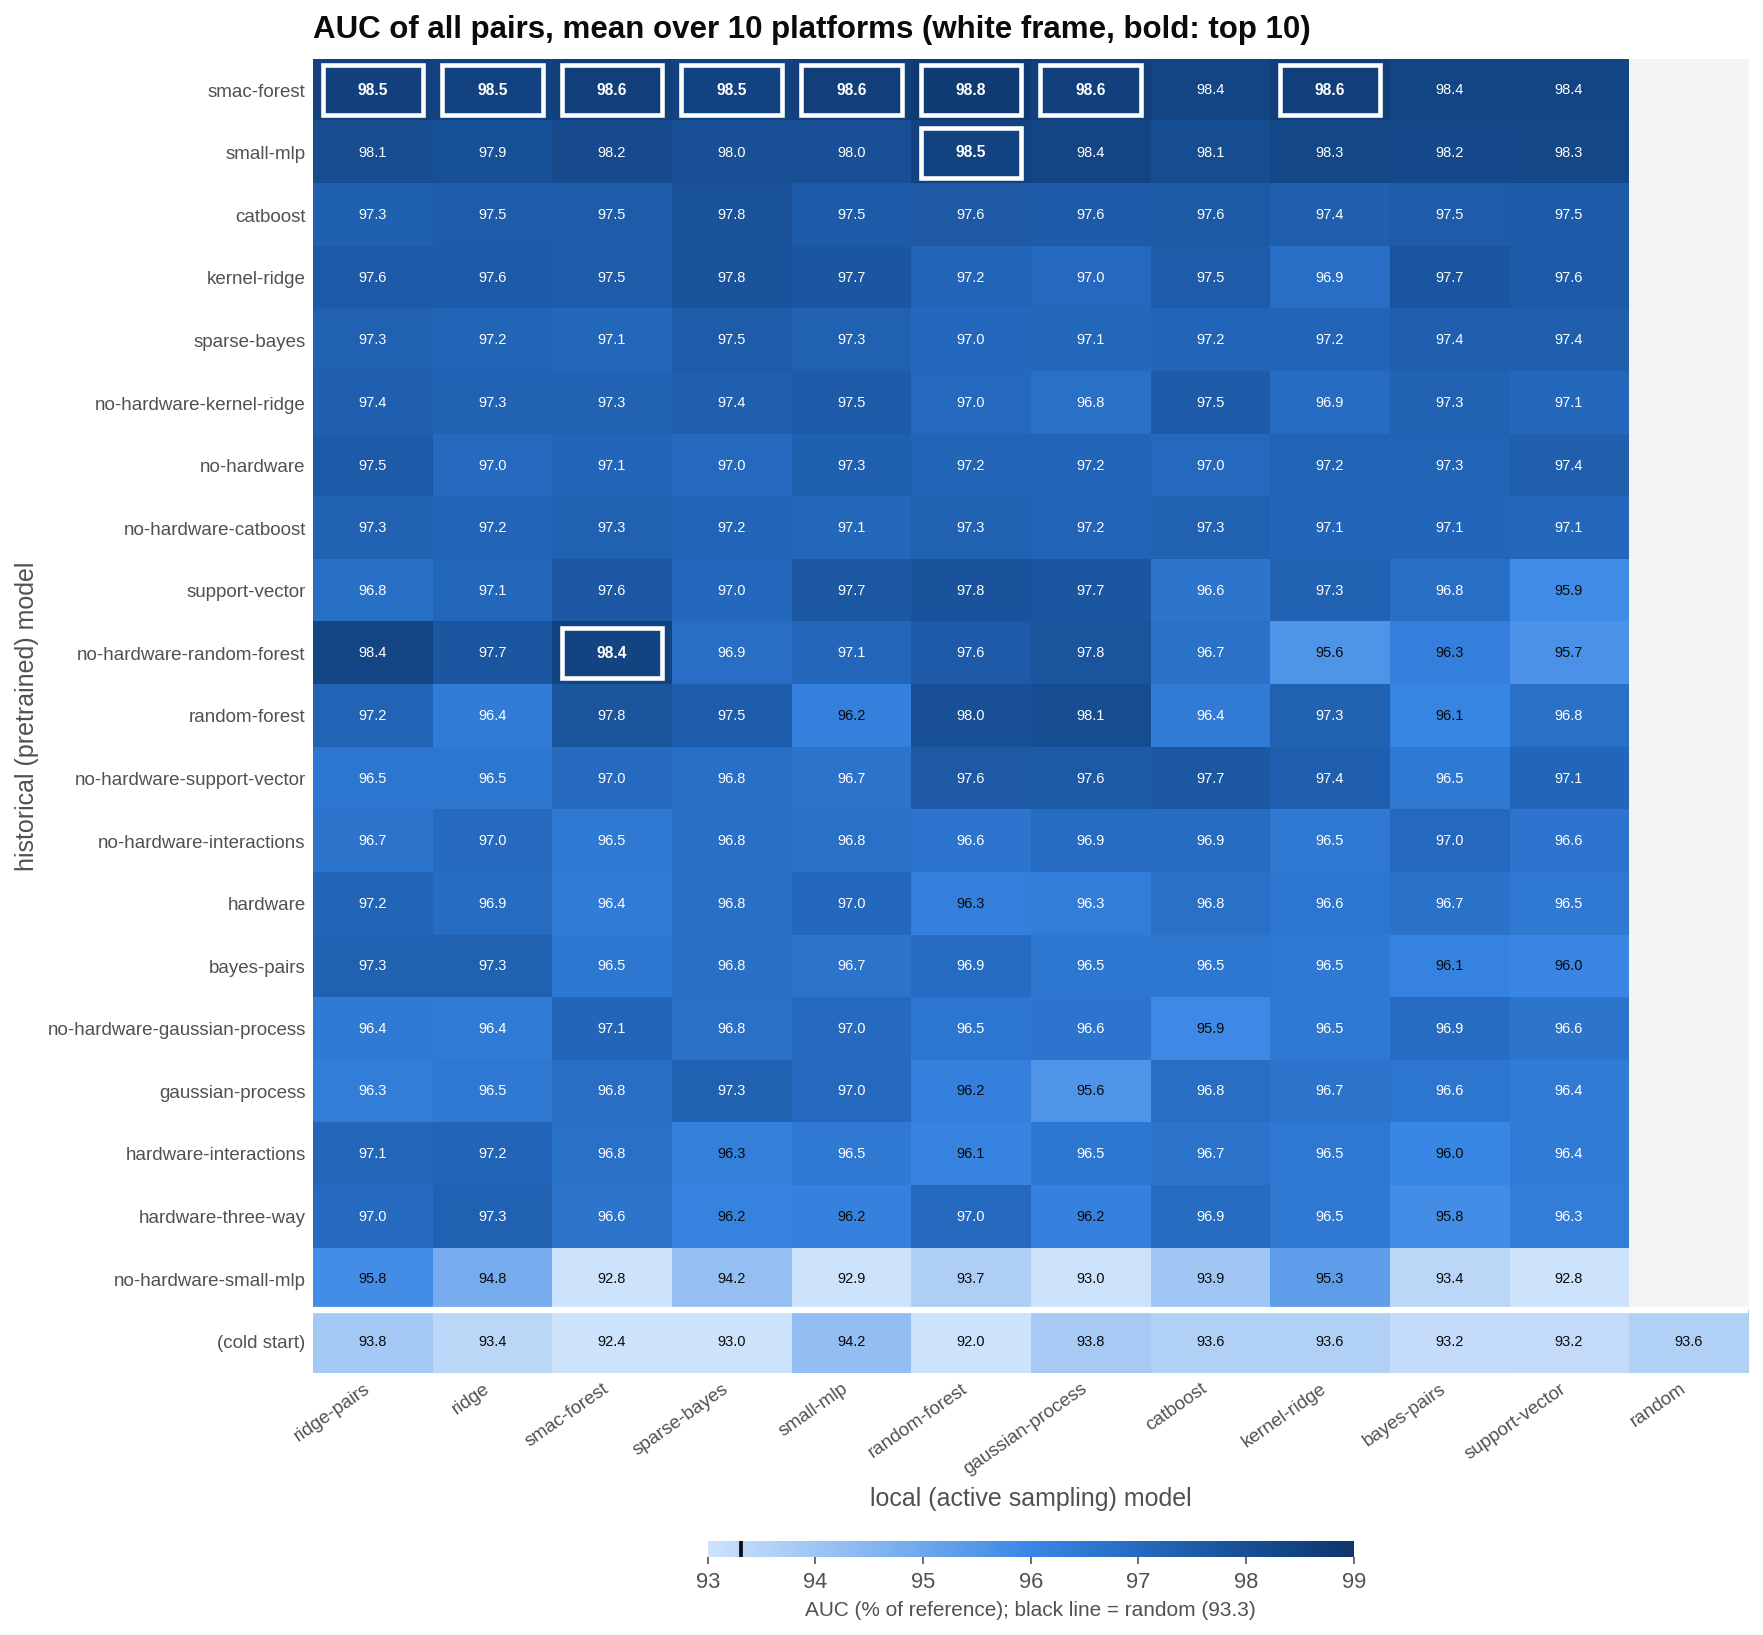

In [39]:
# Figure 6: historical × local heatmap
grid = ranking.auc.unstack("local")
warm_rows = grid.drop(index=COLD, errors="ignore")
grid = grid.reindex(index=warm_rows.mean(axis=1).sort_values(ascending=False).index.tolist()
                    + ([COLD] if COLD in grid.index else []))
grid = grid[grid.mean().sort_values(ascending=False).index]
lo, hi = np.floor(np.nanpercentile(grid, 3)), np.ceil(np.nanmax(grid.to_numpy()))
blues = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
blues.set_bad("#f4f4f2")
fig, ax = plt.subplots(figsize=(max(10, 0.62 * grid.shape[1] + 4.2), 0.36 * grid.shape[0] + 3.2), layout="constrained")
image = ax.imshow(grid.to_numpy(float), cmap=blues, vmin=lo, vmax=hi, aspect="auto", interpolation="nearest")
for i, historical in enumerate(grid.index):
    for j, local in enumerate(grid.columns):
        value = grid.iat[i, j]
        is_top = (historical, local) in TOP
        if np.isfinite(value):
            ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=7.5 if is_top else 7,
                    weight="bold" if is_top else "normal", color="white" if value > lo + 0.55 * (hi - lo) else INK)
        if is_top:
            ax.add_patch(Rectangle((j - 0.42, i - 0.40), 0.84, 0.80, fill=False, ec=SURFACE, lw=2.2))
if COLD in grid.index:
    ax.axhline(len(grid) - 1.5, color=SURFACE, lw=3)
ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=9)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set(xlabel="local (active sampling) model", ylabel="historical (pretrained) model")
bar = fig.colorbar(image, ax=ax, orientation="horizontal", shrink=0.45, aspect=40, pad=0.02)
bar.outline.set_visible(False)
bar.set_label(f"AUC (% of reference); black line = random ({RANDOM_AUC:.1f})", fontsize=10)
bar.ax.axvline(RANDOM_AUC, color=INK, lw=1.8)
ax.set_title(f"AUC of all pairs, mean over {ON_PLATFORMS} (white frame, bold: top {len(TOP)})", **TITLE_STYLE)
plt.show()

## 7. AUC per local model

Each dot is one historical model paired with that local model; the bar is their mean; the diamond is the local model on its own (cold start). Right: how many historical models beat random with this local model.

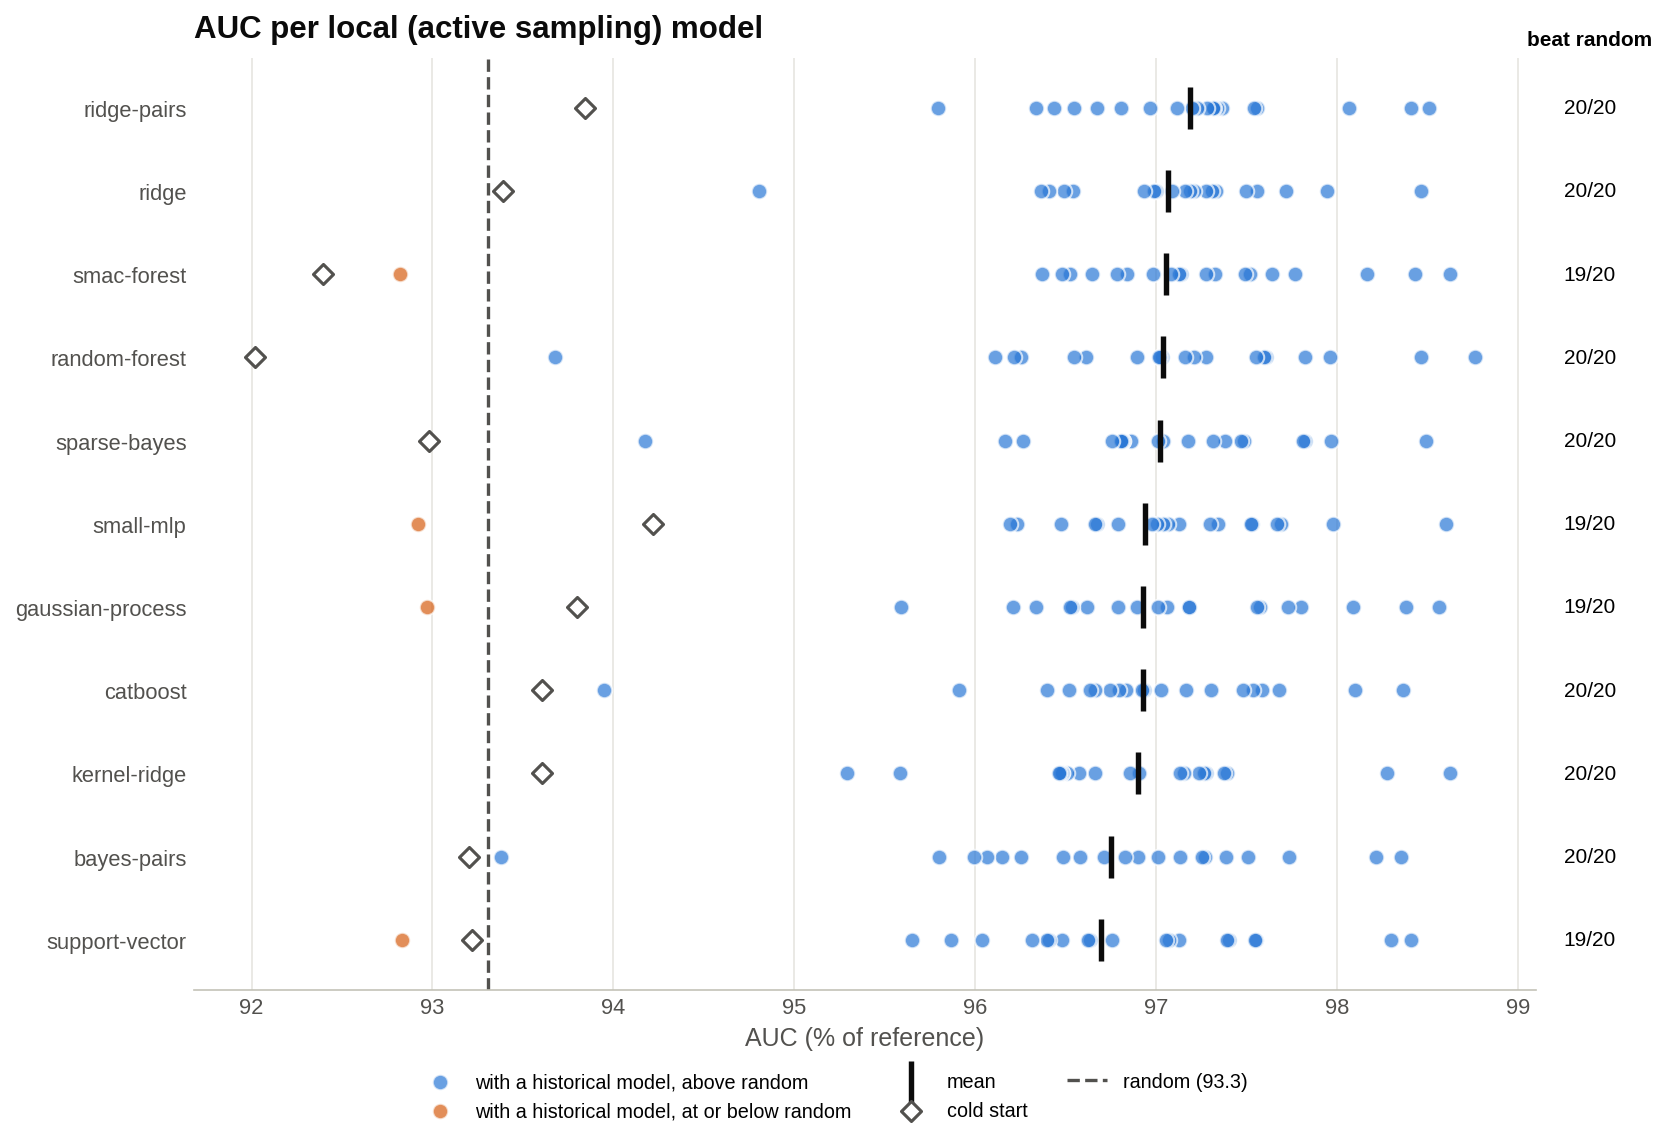

In [40]:
# Figure 7: AUC per active sampling (local) model
warm = ranking.drop(index=COLD, level="historical", errors="ignore").reset_index()
if len(warm):
    order = warm.groupby("local").auc.mean().sort_values().index
    row = {name: i for i, name in enumerate(order)}
    fig, ax = plt.subplots(figsize=(11, 0.5 * len(order) + 2), layout="constrained")
    above = warm.delta > 0
    for points, color, name in ((warm[above], SERIES[0], "above random"), (warm[~above], BELOW, "at or below random")):
        ax.scatter(points.auc, points.local.map(row), s=55, color=color, alpha=0.7, edgecolor=SURFACE,
                   linewidth=1, zorder=3, label=f"with a historical model, {name}")
    mean = warm.groupby("local").auc.mean()
    ax.scatter(mean, mean.index.map(row), marker="|", s=420, color=INK, linewidth=2.6, zorder=4, label="mean")
    cold_points = ranking.loc[COLD].reindex(order).auc.dropna() if COLD in ranking.index.get_level_values(0) else pd.Series(dtype=float)
    ax.scatter(cold_points, cold_points.index.map(row), marker="D", s=46, color=SURFACE, edgecolor=INK2,
               linewidth=1.5, zorder=5, label="cold start")
    ax.axvline(RANDOM_AUC, color=INK2, ls="--", lw=1.6, label=f"random ({RANDOM_AUC:.1f})")
    if np.isfinite(DEFAULT_PCT):
        ax.axvline(DEFAULT_PCT, color=INK, ls=":", lw=1.8, label=f"default build ({DEFAULT_PCT:.1f})")
    counts = above.groupby(warm.local).agg(["sum", "size"]).reindex(order)
    ax.text(1.04, 1.01, "beat random", transform=ax.transAxes, ha="center", va="bottom", fontsize=10, weight="bold")
    for name, (k, n) in counts.iterrows():
        ax.text(1.04, row[name], f"{k}/{n}", transform=ax.get_yaxis_transform(), ha="center", va="center", fontsize=10)
    ax.set_yticks(range(len(order)), order)
    ax.set_ylim(-0.6, len(order) - 0.4)
    ax.spines["left"].set_visible(False)
    style_axis(ax)
    ax.set_xlabel("AUC (% of reference)")
    fig.legend(loc="outside lower center", ncol=3, frameon=False, fontsize=9.5)
    ax.set_title("AUC per local (active sampling) model", **TITLE_STYLE)
    plt.show()

## 8. Where do the top pairs gain?

Δ AUC vs. random per hardware for the top pairs (and the evaluation's own random sessions as a check, expected ≈ 0). Shows whether a lead comes from one machine only.

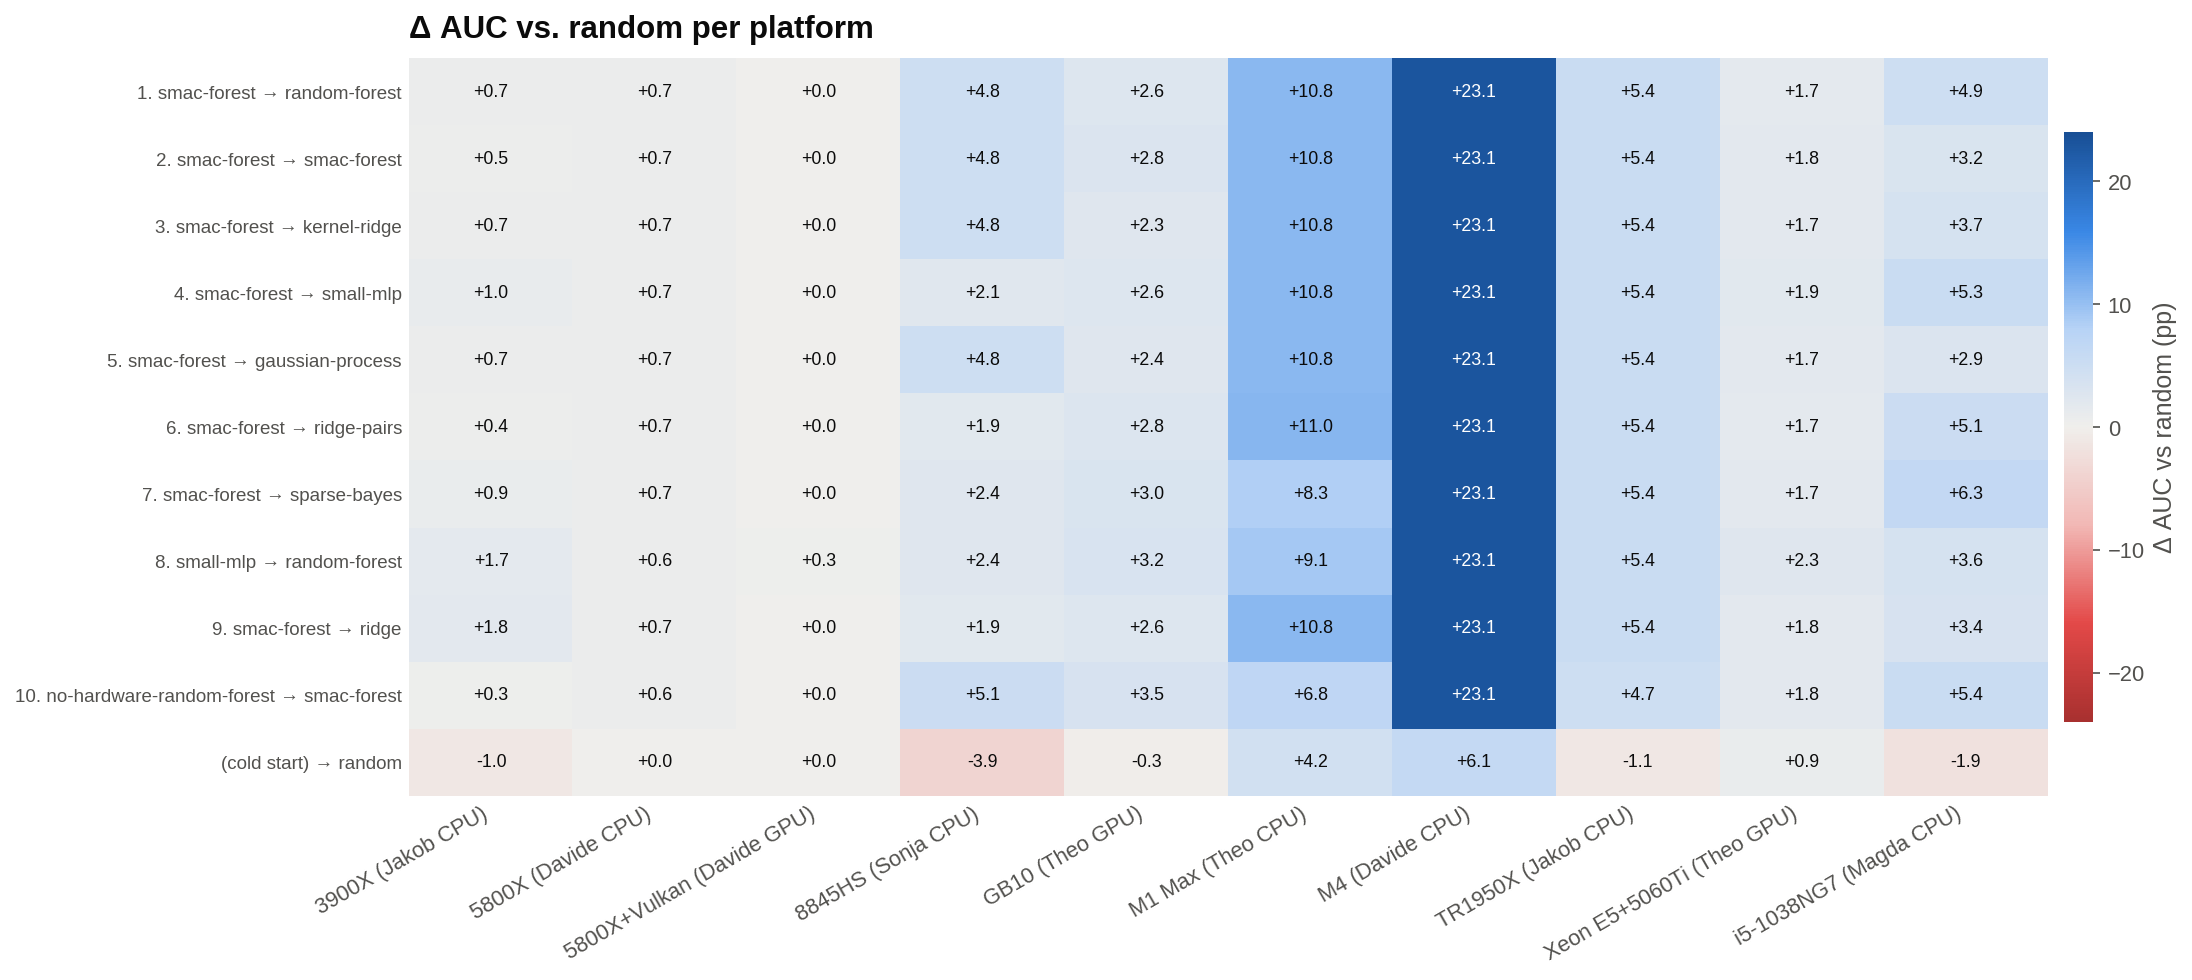

In [41]:
# Figure 8: Δ AUC vs random per platform
rows = TOP + ([RANDOM_PAIR] if RANDOM_PAIR in ranking.index else [])
delta_grid = cell.delta.unstack("platform").reindex(index=rows, columns=PLATFORMS)
limit = max(1.0, np.ceil(np.nanmax(np.abs(delta_grid.to_numpy()), initial=0)))
diverging = LinearSegmentedColormap.from_list("red-gray-blue", ["#a8302f", "#e34948", "#f2b8b5", "#f0efec",
                                                                "#b7d3f6", "#3987e5", "#184f95"])
fig, ax = plt.subplots(figsize=(0.9 * len(PLATFORMS) + 5.5, 0.42 * len(rows) + 1.8), layout="constrained")
image = ax.imshow(delta_grid.to_numpy(float), cmap=diverging, vmin=-limit, vmax=limit, aspect="auto")
for i in range(delta_grid.shape[0]):
    for j in range(delta_grid.shape[1]):
        value = delta_grid.iat[i, j]
        if np.isfinite(value):
            ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=8.5,
                    color="white" if abs(value) > 0.6 * limit else INK)
ax.set_xticks(range(len(PLATFORMS)), PLATFORMS, rotation=30, ha="right")
ax.set_yticks(range(len(rows)), [f"{i}. {label(p)}" if p in TOP else label(p) for i, p in enumerate(rows, 1)], fontsize=9)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
bar = fig.colorbar(image, ax=ax, shrink=0.8, pad=0.01)
bar.outline.set_visible(False)
bar.set_label("Δ AUC vs random (pp)")
ax.set_title("Δ AUC vs. random per platform", **TITLE_STYLE)
plt.show()

## 9. How certain is the top list?

Same bootstrap as in figure 4: 95 % interval of Δ AUC vs. random and how often a pair lands in the top list. Shown for the best 15 pairs.

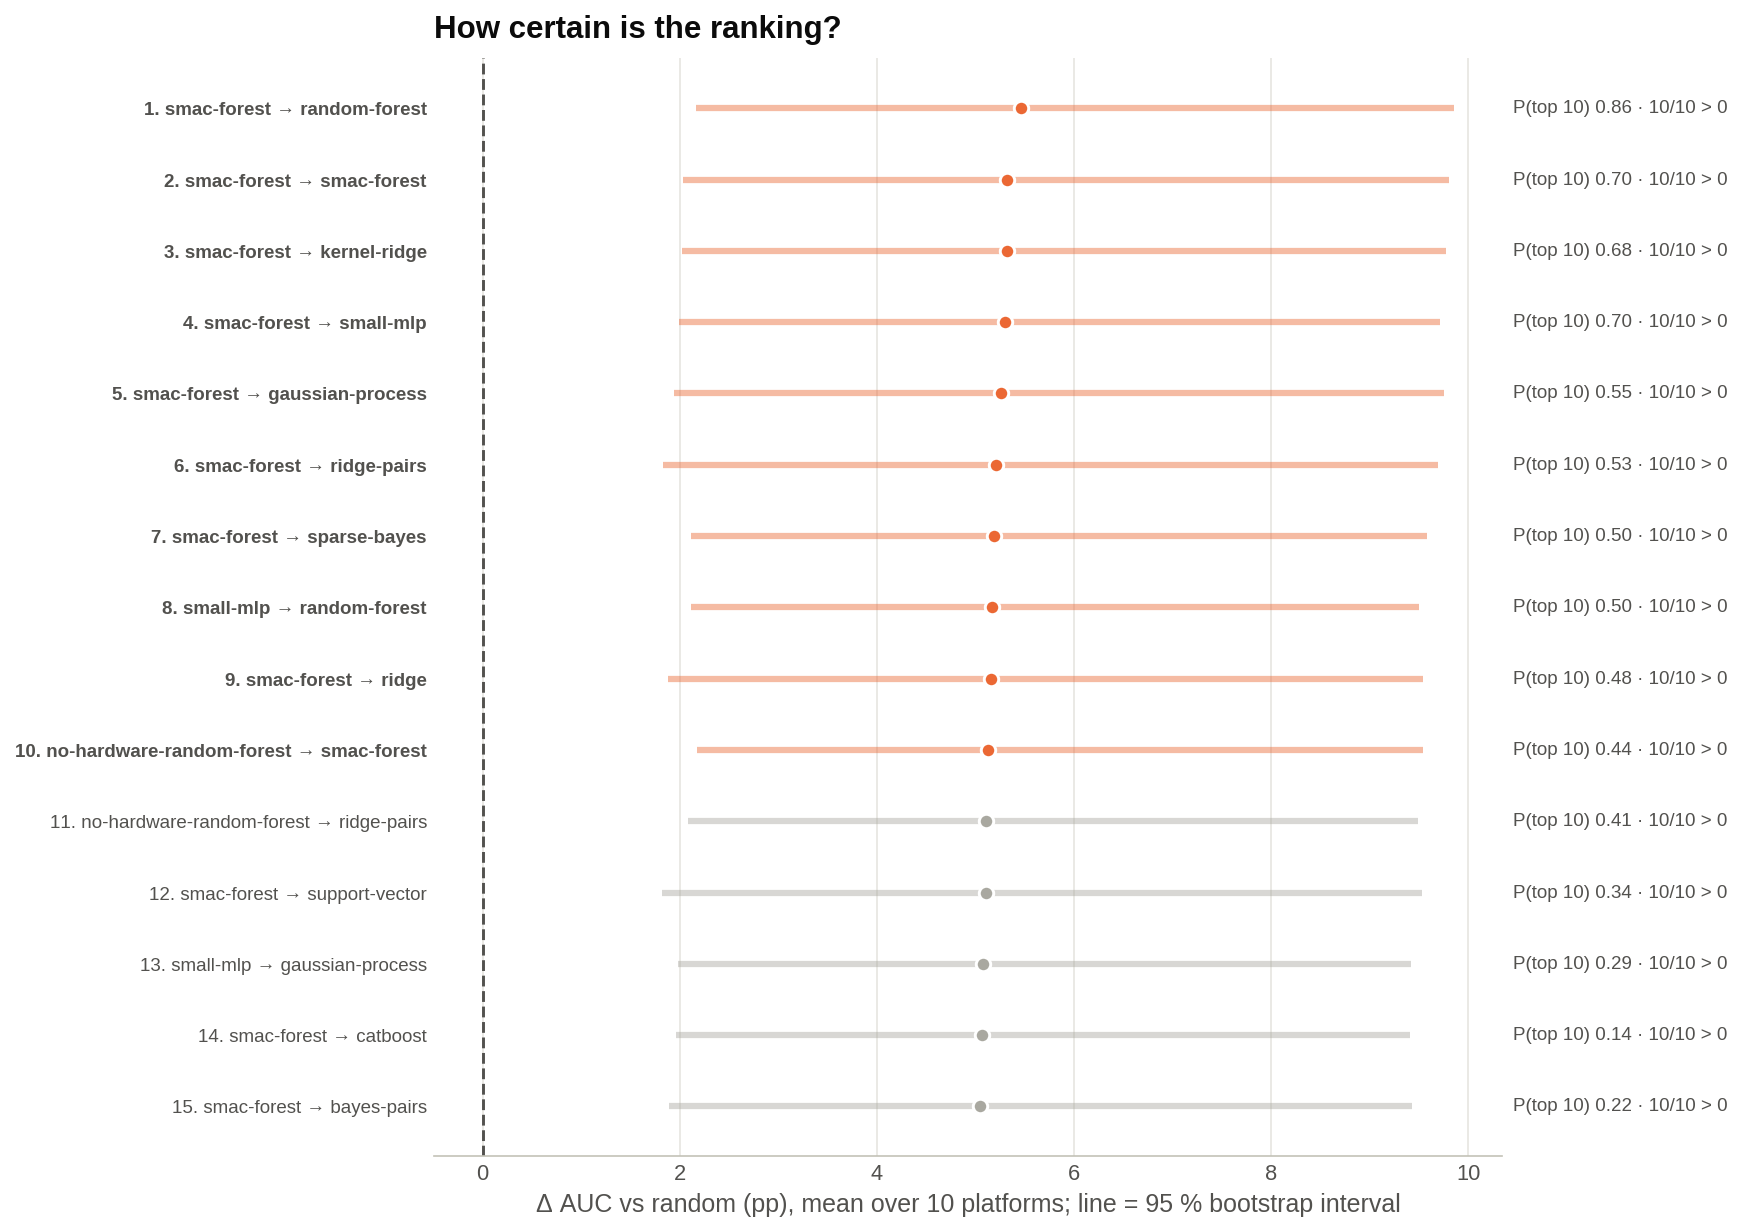

In [42]:
# Figure 9: bootstrap interval and P(top N)
is_candidate = np.array([p in candidates.index for p in ranking.index])
ranks = np.where(is_candidate, np.nan_to_num(boot, nan=-np.inf), -np.inf).argsort(axis=1)[:, ::-1].argsort(axis=1)
certainty = pd.DataFrame({"Δ vs random": delta_by_platform.mean(axis=1),
                          "ci low": np.nanpercentile(boot, 2.5, axis=0), "ci high": np.nanpercentile(boot, 97.5, axis=0),
                          f"P(top {TOP_N})": (ranks < TOP_N).mean(axis=0),
                          "platforms > 0": (delta_by_platform > 0).sum(axis=1)}, index=ranking.index)
shown = ranking.index[:15].tolist()[::-1]
fig, ax = plt.subplots(figsize=(11.5, 0.42 * len(shown) + 1.8), layout="constrained")
ax.axvline(0, color=INK2, ls="--", lw=1.4, label="random (expected)")
for i, pair in enumerate(shown):
    c = certainty.loc[pair]
    color = ACCENT if pair in TOP else OTHER
    ax.hlines(i, c["ci low"], c["ci high"], color=color, lw=3, alpha=0.45)
    ax.scatter(c["Δ vs random"], i, s=48, color=color, edgecolor=SURFACE, linewidth=1.4, zorder=4)
    ax.text(1.01, i, f"P(top {TOP_N}) {c[f'P(top {TOP_N})']:.2f} · {int(c['platforms > 0'])}/{len(PLATFORMS)} > 0",
            transform=ax.get_yaxis_transform(), va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(shown)), [f"{int(ranking.loc[p, 'rank'])}. {label(p)}" for p in shown], fontsize=9)
for tick, pair in zip(ax.get_yticklabels(), shown):
    tick.set_fontweight("bold" if pair in TOP else "normal")
ax.spines["left"].set_visible(False)
style_axis(ax)
ax.set_xlabel(f"Δ AUC vs random (pp), mean over {ON_PLATFORMS}; line = 95 % bootstrap interval")
ax.set_title("How certain is the ranking?", **TITLE_STYLE)
plt.show()

## 10. Tuning time vs. performance gain

- **Model time:** what the models themselves cost per session (refits, picking the next build); the only cost that differs between pairs for the same builds. In simulation it is measured with parallel workers, so compare it relatively.

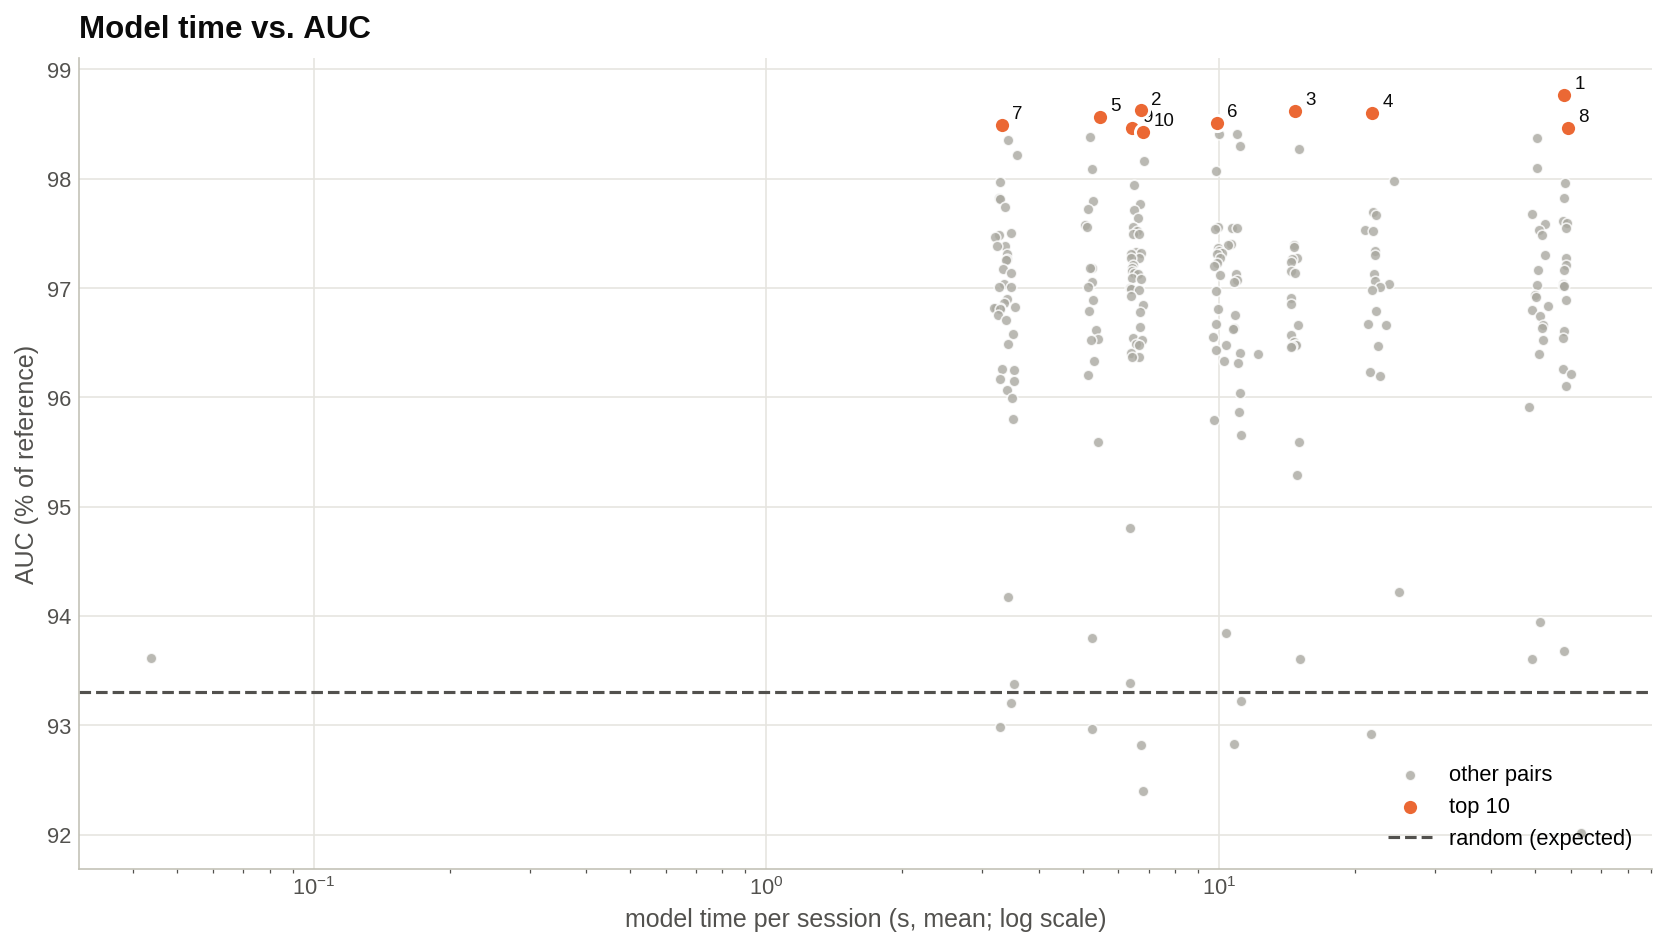

In [43]:
# Figure 10: model time per session vs AUC
fig, ax = plt.subplots(figsize=(11, 6.2), layout="constrained")
others = ranking.drop(index=TOP)
ax.scatter(others["model s / session"], others.auc, s=26, color=OTHER, alpha=0.8, edgecolor=SURFACE, lw=0.8,
           label="other pairs", zorder=2)
tops = ranking.loc[TOP]
ax.scatter(tops["model s / session"], tops.auc, s=60, color=ACCENT, edgecolor=SURFACE, lw=1.4, label=f"top {len(TOP)}", zorder=4)
for rank, pair in enumerate(TOP, 1):
    ax.annotate(str(rank), (tops.loc[pair, "model s / session"], tops.loc[pair, "auc"]), xytext=(5, 3),
                textcoords="offset points", fontsize=9, color=INK)
ax.axhline(RANDOM_AUC, color=INK2, ls="--", lw=1.5, label="random (expected)")
ax.set_xscale("log")
style_axis(ax, "both")
ax.set(xlabel="model time per session (s, mean; log scale)", ylabel="AUC (% of reference)")
ax.legend(loc="lower right", frameon=False)
ax.set_title("Model time vs. AUC", **TITLE_STYLE)
plt.show()

<h3 style="color: red;">Only for LIVE active sampling</h3>

- **Tuning time:** building + benchmarking every attempted build plus model time. Live sessions measure it; simulated ones look up each attempted build's recorded build + benchmark time (platform median where it is missing, e.g. for the start builds).
- **Gain:** best build found vs. the default build, or vs. the **median measured build** until `DEFAULT_BUILD` is set. **Break-even:** hours of running the application with the tuned build until the time it saves equals the tuning time: tuning time / gain.

In [44]:
# Tuning time (h) per session and step
def gap_seconds(frame):
    gaps = frame.start.sort_values().diff().dt.total_seconds()
    return gaps[(gaps > 0) & (gaps < 3 * 3600)].median()


step_seconds = pool.groupby("platform").seconds.median()
estimated = step_seconds.isna()
step_seconds = step_seconds.fillna(pd.Series({p: gap_seconds(f) for p, f in raw.groupby("platform")}, dtype=float))
if estimated.any():
    print("no recorded build times on", list(step_seconds.index[estimated]),
          "→ step time estimated from the gaps between consecutive benchmarks")
lookup = {}
for p, rows in pool.groupby("platform"):
    lookup.update(zip(((p, k) for k in build_keys(rows)), rows.seconds))
sim = ~timings.live
matched = pd.Series([lookup.get(k, np.nan) for k in zip(timings.platform, timings.attempted_build)], index=timings.index)
timings["build_seconds"] = matched.fillna(timings.platform.map(step_seconds))
if sim.any():
    print(f"simulated attempts with a recorded build time: {matched[sim].notna().mean():.0%}")
simulated_seconds = (timings.session_elapsed_seconds + (FIRST - 1) * timings.platform.map(step_seconds)
                     + timings.groupby("sid").build_seconds.cumsum())
timings["tuning_hours"] = np.where(timings.live, timings.session_elapsed_seconds, simulated_seconds) / 3600
hours = timings.pivot_table(index="sid", columns="step", values="tuning_hours", aggfunc="first").reindex(index=sessions.sid, columns=STEPS)

gain_reference = default_perf.reindex(PLATFORMS).fillna(median_perf) if default_perf.size else median_perf
GAIN_NAME = "default build" if default_perf.size else "median measured build"
if default_perf.size and default_perf.reindex(PLATFORMS).isna().any():
    print("default build missing on some platforms → median measured build used there")
gain = 100 * (found.div(sessions.platform.map(gain_reference).to_numpy(), axis=0) - 1)
breakeven = hours / (gain / 100).where(gain > 0)   # hours of running the tuned build until the tuning time is saved


def pair_curves(pair, p):
    mask = (pair_mask(pair) & (sessions.platform == p)).to_numpy()
    return hours[mask].mean(), gain[mask].mean(), breakeven[mask].mean()


random_gain = random_curve.mul(reference.reindex(random_curve.index), axis=0).div(gain_reference.reindex(random_curve.index), axis=0) - 100

simulated attempts with a recorded build time: 100%


In [45]:
# Table: cost and payoff per hardware, for the best pair and random
rows = []
for p in PLATFORMS:
    h, g, b = pair_curves(TOP[0], p)
    rg = random_gain.loc[p, BUDGET] if p in random_gain.index else np.nan
    rows.append({"platform": p, "min per build": step_seconds.get(p, np.nan) / 60,
                 f"tuning h ({BUDGET} builds)": h[BUDGET], f"gain at {BUDGET} (%)": g[BUDGET],
                 f"random gain at {BUDGET} (%)": rg,
                 f"break-even h at {BUDGET}": b[BUDGET],
                 "best stop (builds)": b.idxmin() if b.notna().any() else np.nan, "break-even h there": b.min()})
payoff = pd.DataFrame(rows).set_index("platform")
display(Markdown(
    f"**Best pair:** `{label(TOP[0])}`. *at {BUDGET}* = after {BUDGET} builds; *gain* = how much faster the best build found "
    f"is than the {GAIN_NAME}; *break-even h* = hours of running the application with that build until the time it saves "
    f"equals the tuning time (tuning h / gain); *best stop* = number of builds with the shortest break-even, "
    f"*break-even h there* = that break-even."))
display(payoff.style.format(precision=1, na_rep="–"))

**Best pair:** `smac-forest → random-forest`. *at 25* = after 25 builds; *gain* = how much faster the best build found is than the median measured build; *break-even h* = hours of running the application with that build until the time it saves equals the tuning time (tuning h / gain); *best stop* = number of builds with the shortest break-even, *break-even h there* = that break-even.

,min per build,tuning h (25 builds),gain at 25 (%),random gain at 25 (%),break-even h at 25,best stop (builds),break-even h there
platform,,,,,,,
3900X (Jakob CPU),2.7,1.2,9.5,10.1,12.1,3,2.0
5800X (Davide CPU),1.6,0.7,4.6,4.4,15.2,3,1.8
5800X+Vulkan (Davide GPU),1.5,0.7,1.4,1.4,48.5,3,5.9
8845HS (Sonja CPU),3.4,2.2,58.7,57.5,3.7,3,0.3
GB10 (Theo GPU),1.2,0.7,10.4,8.1,6.3,3,0.9
M1 Max (Theo CPU),1.3,0.5,119.5,110.6,0.4,3,0.1
M4 (Davide CPU),2.7,1.1,156.3,124.1,0.7,3,0.1
TR1950X (Jakob CPU),3.2,1.4,52.0,47.8,2.7,3,0.3
Xeon E5+5060Ti (Theo GPU),10.4,5.0,10.1,9.6,49.0,3,7.4


<p style="color: red;"><strong>TODO: Plot measured predictions and selected outputs.</strong> For simulation and live runs, plot the measured recommendation, the best sampled build and the output that would be selected at each stopping point. Show prediction and measurement time separately. Highlight the final check after step 25 and account for its cost when comparing tuning time against gain.</p>

## 11. Summary

In [46]:
cold_best = [p for p in ranking.index if p[0] == COLD and p != RANDOM_PAIR]
lines = [f"- **Data:** {len(sessions)} sessions ({int((~sessions.live).sum())} simulated, {int(sessions.live.sum())} live), "
         f"{len(ranking)} pairs, {len(PLATFORMS)} platforms ({', '.join(PLATFORMS)}).",
         f"- **Random (expected) AUC:** {RANDOM_AUC:.2f}; pairs above it: {(ranking.delta > 0).sum()} of {len(ranking)}.",
         f"- **Top {len(TOP)}:** " + "; ".join(f"{i}. `{label(p)}` ({ranking.loc[p, 'auc']:.2f}, Δ {ranking.loc[p, 'delta']:+.2f})"
                                          for i, p in enumerate(TOP, 1)) + ".",
         f"- **Cold start:** best `{label(cold_best[0]) if len(cold_best) else '–'}`; "
         f"historical models among the top {len(TOP)}: {len(hist_order)}, local models: {len(local_order)}.",
         f"- **Flags noticeable** (median build further from best than 2 × noise): "
         + ", ".join(f"{p} ({100 - spread.loc[p, 'median (%)']:.1f} % vs {spread.loc[p, 'noise (%)']:.2f} %)"
                     for p in spread.index[spread.noticeable]) + "; not: "
         + (", ".join(spread.index[~spread.noticeable]) or "–") + "."]
display(Markdown("\n".join(lines)))

- **Data:** 2560 sessions (2560 simulated, 0 live), 232 pairs, 10 platforms (3900X (Jakob CPU), 5800X (Davide CPU), 5800X+Vulkan (Davide GPU), 8845HS (Sonja CPU), GB10 (Theo GPU), M1 Max (Theo CPU), M4 (Davide CPU), TR1950X (Jakob CPU), Xeon E5+5060Ti (Theo GPU), i5-1038NG7 (Magda CPU)).
- **Random (expected) AUC:** 93.31; pairs above it: 223 of 232.
- **Top 10:** 1. `smac-forest → random-forest` (98.76, Δ +5.46); 2. `smac-forest → smac-forest` (98.62, Δ +5.32); 3. `smac-forest → kernel-ridge` (98.62, Δ +5.32); 4. `smac-forest → small-mlp` (98.60, Δ +5.30); 5. `smac-forest → gaussian-process` (98.57, Δ +5.26); 6. `smac-forest → ridge-pairs` (98.51, Δ +5.20); 7. `smac-forest → sparse-bayes` (98.49, Δ +5.18); 8. `small-mlp → random-forest` (98.47, Δ +5.16); 9. `smac-forest → ridge` (98.46, Δ +5.16); 10. `no-hardware-random-forest → smac-forest` (98.43, Δ +5.13).
- **Cold start:** best `(cold start) → small-mlp`; historical models among the top 10: 3, local models: 8.
- **Flags noticeable** (median build further from best than 2 × noise): M4 (Davide CPU) (61.0 % vs 11.04 %), M1 Max (Theo CPU) (55.1 % vs 2.20 %), 8845HS (Sonja CPU) (37.0 % vs 6.17 %), TR1950X (Jakob CPU) (34.2 % vs 1.79 %), i5-1038NG7 (Magda CPU) (33.8 % vs 2.57 %), 3900X (Jakob CPU) (11.7 % vs 2.71 %), Xeon E5+5060Ti (Theo GPU) (9.6 % vs 0.33 %), GB10 (Theo GPU) (9.4 % vs 0.17 %), 5800X (Davide CPU) (4.9 % vs 0.06 %), 5800X+Vulkan (Davide GPU) (1.6 % vs 0.05 %); not: –.